# Import bibliotek i konfiguracja wykresów


In [615]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score
)

from lightgbm import LGBMClassifier, LGBMRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

colors = ["#4990E1", "#7B2CBF", "#EC35D3", "#D43971", "#A4133C", "#350C58", "#F77F00", "#2A9D8F", "#F2C216", "#77E402AA"]

# Wczytanie danych źródłowych


In [616]:
files = [
    "kola_klinowe",
    "kola_lancuchowe",
    "kola_modulowe",
    "kola_zebate",
    "lancuchy_IWIS",
    "lancuchy_standardowe",
    "listwy_modulowe",
    "napinacze",
    "normalia_halder",
    "normalia_pozostale",
    "pasy_klinowe",
    "pasy_zebate_gates",
    "pasy_zebate_PU",
    "plytki_mocujace",
    "prowadnice",
    "przeguby",
    "sprzegla",
    "sruby_i_nakretki",
    "tuleje",
    "waly_i_tuleje"
]

datasets = {}

for file in files:
    datasets[file] = pd.read_csv(
        f"{file}.csv",
        sep=";",
        encoding="cp1250",
        header=2
    )

# Kontrola danych surowych


Kontrola liczby rekordów i struktury

In [617]:
dataset_sizes = pd.Series({
    name: len(df_temp)
    for name, df_temp in datasets.items()
}).sort_values(ascending=False)

display(dataset_sizes)

lancuchy_IWIS           3566
lancuchy_standardowe    3414
tuleje                  2565
kola_zebate             2311
kola_lancuchowe         1263
sruby_i_nakretki        1138
kola_modulowe           1118
napinacze               1092
sprzegla                 909
waly_i_tuleje            807
pasy_zebate_PU           797
pasy_zebate_gates        796
plytki_mocujace          700
normalia_pozostale       677
pasy_klinowe             456
prowadnice               393
kola_klinowe             302
normalia_halder          235
listwy_modulowe          203
przeguby                 188
dtype: int64

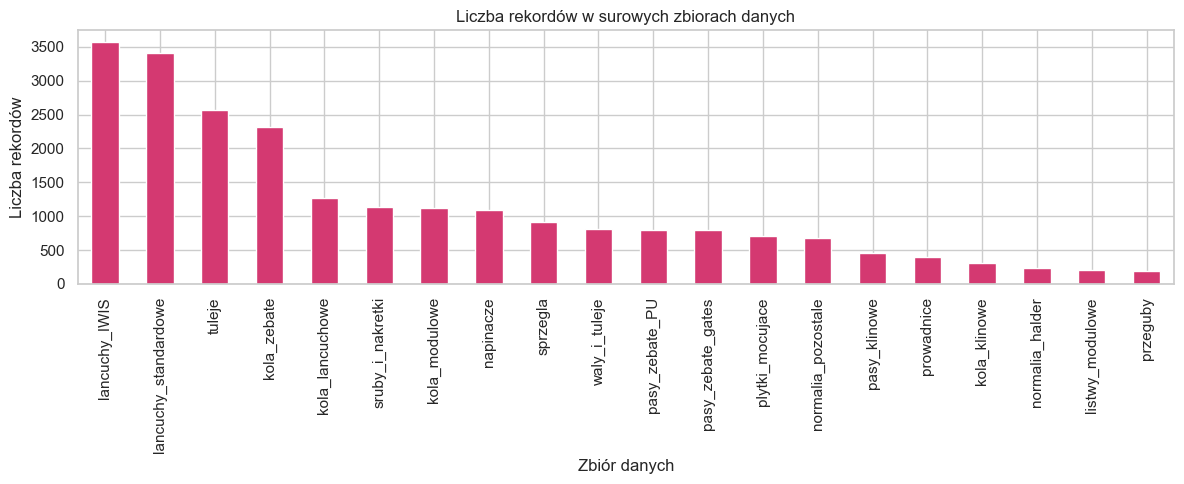

In [618]:
plt.figure(figsize=(12, 5))

dataset_sizes.plot(
    kind="bar",
    color=colors[3]
)

plt.title("Liczba rekordów w surowych zbiorach danych")
plt.xlabel("Zbiór danych")
plt.ylabel("Liczba rekordów")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [619]:
structure_check = pd.DataFrame({
    "liczba_kolumn": {
        name: df_temp.shape[1]
        for name, df_temp in datasets.items()
    },
    "liczba_rekordow": {
        name: df_temp.shape[0]
        for name, df_temp in datasets.items()
    }
})

display(structure_check.sort_values("liczba_kolumn"))

,liczba_kolumn,liczba_rekordow
normalia_halder,5,235
kola_klinowe,7,302
kola_modulowe,7,1118
kola_lancuchowe,7,1263
lancuchy_IWIS,7,3566
lancuchy_standardowe,7,3414
listwy_modulowe,7,203
kola_zebate,7,2311
napinacze,7,1092
normalia_pozostale,7,677


Usunięcie zbioru o innej strukturze (występują tam dane roczne a na późniejszym etapie do prognozowania używamy agregacji miesięcznej)

In [620]:
removed = datasets.pop("normalia_halder", None)

print(
    "Usunięto normalia_halder"
    if removed is not None
    else "normalia_halder nie było w datasets"
)

Usunięto normalia_halder


Połączenie danych RAW

In [621]:
raw_all = pd.concat(
    datasets.values(),
    ignore_index=True
)

print("Shape raw_all:", raw_all.shape)
display(raw_all.head())

Shape raw_all: (22695, 7)


,Produkt.Nazwa,Produkt.Symbol,Produkt.Jednostka podstawowa,Czas.Kalendarzowy.Rok,Czas.Kalendarzowy.Data,Dokument.Dokument.Rodzaj.Typ dokumentu,Sprzedaż Ilość
0,Koło pasowe Micro - V 224L16,PYB224L16 TB3020,szt,2020,25.03.2020,WZ,2
1,Koło pasowe Micro - V 224L16,PYB224L16 TB3020,szt,2020,28.04.2020,WZ,4
2,Koło pasowe Micro - V 224L16,PYB224L16 TB3020,szt,2020,18.06.2020,WZ,5
3,Koło pasowe Micro - V 224L16,PYB224L16 TB3020,szt,2020,29.06.2020,WZ,5
4,Koło pasowe Micro - V 224L16,PYB224L16 TB3020,szt,2020,10.08.2020,WZ,10


Analiza braków danych RAW

In [622]:
raw_missing_percent = pd.DataFrame({
    name: round(df_temp.isna().mean() * 100, 2)
    for name, df_temp in datasets.items()
}).T

display(raw_missing_percent)

,Produkt.Nazwa,Produkt.Symbol,Produkt.Jednostka podstawowa,Czas.Kalendarzowy.Rok,Czas.Kalendarzowy.Data,Dokument.Dokument.Rodzaj.Typ dokumentu,Sprzedaż Ilość
kola_klinowe,0.00,0.33,0.33,4.30,19.87,19.87,0.0
kola_lancuchowe,0.00,0.08,0.08,1.50,8.47,8.47,0.0
kola_modulowe,0.00,0.09,0.09,2.86,16.73,16.73,0.0
kola_zebate,0.04,0.04,0.04,2.51,14.15,14.37,0.0
lancuchy_IWIS,0.00,0.03,0.03,0.81,5.33,5.44,0.0
lancuchy_standardowe,0.03,0.03,0.03,0.76,4.66,5.13,0.0
listwy_modulowe,0.00,0.00,0.00,0.49,3.45,3.94,0.0
napinacze,0.00,0.09,0.09,1.56,9.43,9.52,0.0
normalia_pozostale,0.00,0.15,0.15,4.43,18.91,18.91,0.0
pasy_klinowe,0.00,0.22,0.22,4.17,16.01,16.01,0.0


# Czyszczenie danych

In [623]:
raw_columns = [
    "Produkt.Nazwa",
    "Produkt.Symbol",
    "Produkt.Jednostka podstawowa",
    "Czas.Kalendarzowy.Rok",
    "Czas.Kalendarzowy.Data",
    "Dokument.Dokument.Rodzaj.Typ dokumentu",
    "Sprzedaż Ilość"
]

new_columns = [
    "nazwa_produktu",
    "symbol_produktu",
    "jednostka",
    "rok",
    "data",
    "typ_dokumentu",
    "sprzedaz_ilosc"
]

In [624]:
for name, df_temp in datasets.items():
    if df_temp.columns.tolist() != raw_columns:
        print(f"Problem z kolumnami: {name}")

In [625]:
for name, df_temp in datasets.items():

    df_temp = df_temp.dropna(subset=[
        "Czas.Kalendarzowy.Data",
        "Dokument.Dokument.Rodzaj.Typ dokumentu"
    ]).copy()

    df_temp.columns = new_columns

    df_temp["data"] = pd.to_datetime(
        df_temp["data"],
        format="%d.%m.%Y",
        errors="coerce"
    )

    df_temp["sprzedaz_ilosc"] = pd.to_numeric(
        df_temp["sprzedaz_ilosc"]
        .astype(str)
        .str.strip()
        .str.replace("\xa0", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

    df_temp["rok"] = pd.to_numeric(
        df_temp["rok"],
        errors="coerce"
    ).astype("Int64")

    df_temp["grupa"] = name

    datasets[name] = df_temp

Połączenie danych po czyszczeniu

W kolumnie ilości sprzedaży występowały wartości zapisane w różnych formatach liczbowych, m.in. z separatorem tysięcy oraz przecinkiem dziesiętnym. Przed konwersją do typu numerycznego wartości zostały ujednolicone poprzez usunięcie separatorów tysięcy oraz zamianę przecinka dziesiętnego na kropkę.

In [626]:
df_all = pd.concat(
    datasets.values(),
    ignore_index=True
)

df_all = df_all[
    ~df_all["nazwa_produktu"]
    .astype(str)
    .str.contains("Razem|Suma końcowa", case=False, na=False)
].copy()

df_all["jednostka"] = (
    df_all["jednostka"]
    .astype(str)
    .str.strip()
    .str.replace("szt.", "szt", regex=False)
)

df_all["produkt_id"] = (
    df_all["symbol_produktu"].astype(str)
    + " | "
    + df_all["nazwa_produktu"].astype(str)
)

cat_cols = [
    "nazwa_produktu",
    "symbol_produktu",
    "produkt_id",
    "jednostka",
    "typ_dokumentu",
    "grupa"
]

for col in cat_cols:
    df_all[col] = df_all[col].astype("category")

df_all = df_all.sort_values([
    "produkt_id",
    "data"
]).reset_index(drop=True)

Przed rozpoczęciem analizy konieczne było jednoznaczne zdefiniowanie produktu. W badaniu przyjęto, że produkt identyfikowany jest na podstawie kombinacji symbolu produktu oraz nazwy produktu. Podejście to wynikało z faktu, że w danych występowały przypadki produktów posiadających ten sam symbol, lecz różniących się nazwą, co w rzeczywistości oznaczało odrębne produkty.

Kontrola danych po czyszczeniu

In [627]:
print("Shape df_all:", df_all.shape)

print("\nBraki danych:")
display(df_all.isna().sum())

print("\nTypy danych:")
display(df_all.dtypes)

print("\nZakres dat:")
print(df_all["data"].min(), "-", df_all["data"].max())

print("\nLiczba grup:", df_all["grupa"].nunique())
print("Liczba produktów:", df_all["produkt_id"].nunique())
print("Duplikaty:", df_all.duplicated().sum())

print("\nZera sprzedażowe:")
print((df_all["sprzedaz_ilosc"] == 0).sum())

print("\nUjemna sprzedaż:")
print((df_all["sprzedaz_ilosc"] < 0).sum())

Shape df_all: (20190, 9)

Braki danych:


nazwa_produktu     0
symbol_produktu    0
jednostka          0
rok                0
data               0
typ_dokumentu      0
sprzedaz_ilosc     0
grupa              0
produkt_id         0
dtype: int64


Typy danych:


nazwa_produktu           category
symbol_produktu          category
jednostka                category
rok                         Int64
data               datetime64[ns]
typ_dokumentu            category
sprzedaz_ilosc            float64
grupa                    category
produkt_id               category
dtype: object


Zakres dat:
2020-01-07 00:00:00 - 2025-12-19 00:00:00

Liczba grup: 19
Liczba produktów: 468
Duplikaty: 0

Zera sprzedażowe:
223

Ujemna sprzedaż:
0


In [628]:
display(df_all["jednostka"].value_counts())

jednostka
szt    15179
m       4469
mm       425
Şbr       60
par       57
Name: count, dtype: int64

In [629]:
# mm -> m

mask = df_all["jednostka"] == "mm"

df_all.loc[mask, "sprzedaz_ilosc"] = (
    df_all.loc[mask, "sprzedaz_ilosc"] / 1000
)

df_all.loc[mask, "jednostka"] = "m"

display(df_all["jednostka"].value_counts())

jednostka
szt    15179
m       4894
Şbr       60
par       57
mm         0
Name: count, dtype: int64

W przypadku wybranych jednostek dokonano podstawowego ujednolicenia skali. Wartości zapisane w milimetrach przeliczono na metry, aby ograniczyć niespójność jednostek miary w danych. 
Şbr-ta jednosta oznacza "żebra"

Kontrola jednostek w obrębie produktu

In [630]:
unit_check = (
    df_all
    .groupby("produkt_id", observed=True)["jednostka"]
    .nunique()
    .sort_values(ascending=False)
)

unit_problem = unit_check[unit_check > 1]

if unit_problem.empty:
    print("W obrębie jednego produktu (symbol_produktu + nazwa_produktu) nie występują różne jednostki miary.")
else:
    display(unit_problem)

W obrębie jednego produktu (symbol_produktu + nazwa_produktu) nie występują różne jednostki miary.


Kontrola typów dokumentów

In [631]:
doc_types = (
    df_all["typ_dokumentu"]
    .value_counts(dropna=False)
    .to_frame("liczba")
)

display(doc_types)

,liczba
typ_dokumentu,
WZ,16364
WZE,3535
FSL,223
PA,68


FSL nie reprezentuje rzeczywistej sprzedaży magazynowej. Czyli: 

-nie oznacza faktycznego wydania produktu,

-nie generuje ruchu magazynowego,

-nie odzwierciedla realnego popytu,

Należy usunąć ten typ dokumentu.

In [632]:
df_all = df_all[
    df_all["typ_dokumentu"] != "FSL"
]

display(df_all["typ_dokumentu"].value_counts())

typ_dokumentu
WZ     16364
WZE     3535
PA        68
FSL        0
Name: count, dtype: int64

Kontrola duplikatów biznesowych

In [633]:
business_duplicates = df_all.duplicated(
    subset=[
        "produkt_id",
        "data",
        "typ_dokumentu",
        "sprzedaz_ilosc"
    ],
    keep=False
)

print("Liczba potencjalnych duplikatów biznesowych:", business_duplicates.sum())

Liczba potencjalnych duplikatów biznesowych: 0


Zakres dat per grupa

In [634]:
date_range_by_group = (
    df_all
    .groupby("grupa", observed=True)
    .agg(
        data_min=("data", "min"),
        data_max=("data", "max"),
        liczba_rekordow=("data", "size"),
        liczba_produktow=("produkt_id", "nunique")
    )
    .sort_values("liczba_rekordow", ascending=False)
)

display(date_range_by_group)

,data_min,data_max,liczba_rekordow,liczba_produktow
grupa,,,,
lancuchy_IWIS,2020-01-07,2025-12-19,3355,28
lancuchy_standardowe,2020-01-08,2025-12-19,3185,25
tuleje,2020-01-07,2025-12-19,2312,35
kola_zebate,2020-01-07,2025-12-19,1950,57
kola_lancuchowe,2020-01-07,2025-12-12,1156,18
sruby_i_nakretki,2020-01-07,2025-12-16,973,24
napinacze,2020-01-07,2025-12-16,973,16
kola_modulowe,2020-01-10,2025-12-19,925,31
sprzegla,2020-01-07,2025-12-17,759,27


## Eksploracyjna analiza sprzedaży

In [635]:
sales_stats = (
    df_all["sprzedaz_ilosc"]
    .describe()
    .to_frame("sprzedaz_ilosc")
)

display(sales_stats)

,sprzedaz_ilosc
count,19967.000000
mean,23.253473
std,174.029791
min,0.009000
25%,2.000000
50%,5.030000
75%,15.000000
max,15000.000000


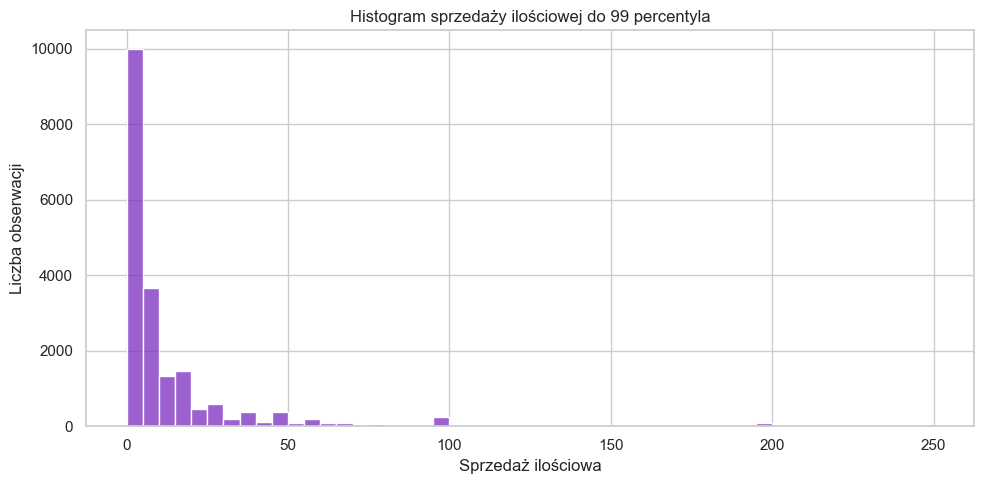

In [636]:
q99 = df_all["sprzedaz_ilosc"].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_all[df_all["sprzedaz_ilosc"] <= q99],
    x="sprzedaz_ilosc",
    bins=50,
    color=colors[1]
)

plt.title("Histogram sprzedaży ilościowej do 99 percentyla")
plt.xlabel("Sprzedaż ilościowa")
plt.ylabel("Liczba obserwacji")
plt.tight_layout()
plt.show()

Rpzkład charakteryzuje się wyraźną prawostronną asymetrią. Zdecydowana większość obserwacji dotyczy stosunkowo małych wielkości sprzedaży, natomiast obserwacje o większych wartościach występują znacznie rzadziej. Nieliczne obserwacje występują również dla wartości przekraczających 50 jednostek, a także w okolicach 100 i 200 jednostek. Asymetria pozostaje widoczna nawet po ograniczeniu zakresu danych do 99. percentyla danych. Pomimo pominięcia największych wartości nadal można zaobserwować znaczne zróżnicowanie wielkości realizowanej sprzedaży.

EDA - grupy produktowe

In [637]:
group_sales = (
    df_all
    .groupby("grupa", observed=True)
    .agg(
        liczba_rekordow=("sprzedaz_ilosc", "size"),
        liczba_produktow=("produkt_id", "nunique"),
    )
    .sort_values("liczba_rekordow", ascending=False)
)

display(group_sales)

,liczba_rekordow,liczba_produktow
grupa,,
lancuchy_IWIS,3355,28
lancuchy_standardowe,3185,25
tuleje,2312,35
kola_zebate,1950,57
kola_lancuchowe,1156,18
sruby_i_nakretki,973,24
napinacze,973,16
kola_modulowe,925,31
sprzegla,759,27


EDA - długości szeregów

In [638]:
series_lengths = (
    df_all
    .groupby("produkt_id", observed=True)
    .agg(
        data_min=("data", "min"),
        data_max=("data", "max"),
        liczba_obserwacji=("data", "size"),
        grupa=("grupa", "first")
    )
    .sort_values("liczba_obserwacji")
)

#display(series_lengths.head(15))
display(series_lengths["liczba_obserwacji"].describe())

count    468.000000
mean      42.664530
std       51.319387
min        1.000000
25%       10.000000
50%       27.000000
75%       53.250000
max      366.000000
Name: liczba_obserwacji, dtype: float64

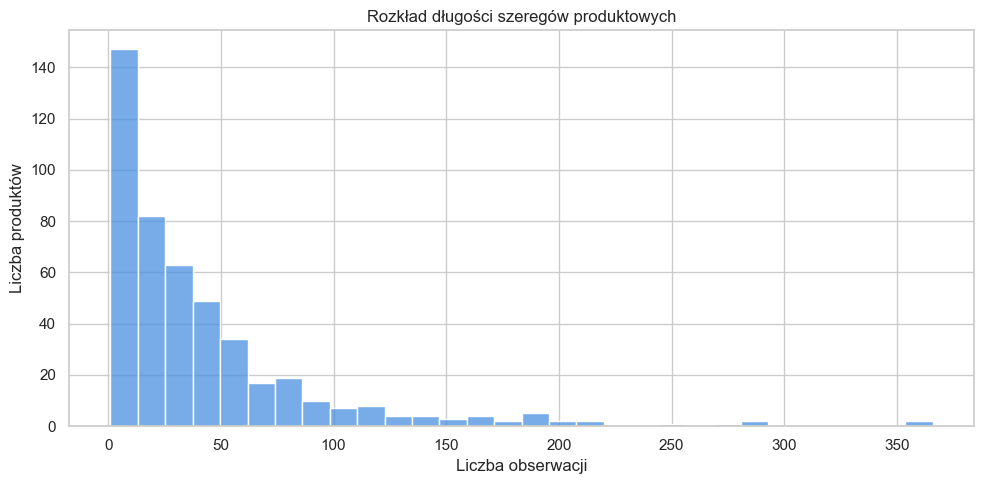

In [639]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=series_lengths,
    x="liczba_obserwacji",
    bins=30,
    color=colors[0]
)

plt.title("Rozkład długości szeregów produktowych")
plt.xlabel("Liczba obserwacji")
plt.ylabel("Liczba produktów")
plt.tight_layout()
plt.show()

Rozkład długości szeregów czasowych wskazuje na znaczne zróżnicowanie liczby obserwacji. Zdecydowana większość produktów posiada stosunkowo krótkie szeregi, obejmujące mniej niż 50 obserwacji. Wraz ze wzrostem długości szeregu liczba produktów wyraźnie maleje. Szeregi przekraczające 100 obserwacji występują znacznie rzadziej, natomiast bardzo długie szeregi, liczące około 300-370 obserwacji, dotyczą jedynie pojedynczych produktów. Oznacza to, że dostępna historia sprzedaży jest niejednorodna, a dla dużej części produktów możliwość identyfikowania stabilnych wzorców na podstawie długiej historii jest ograniczona.

EDA - sprzedaż miesięczna globalnie

In [640]:
monthly_sales_global = (
    df_all
    .assign(miesiac=lambda x: x["data"].dt.to_period("M").dt.to_timestamp())
    .groupby("miesiac", observed=True)["sprzedaz_ilosc"]
    .sum()
    .reset_index()
)

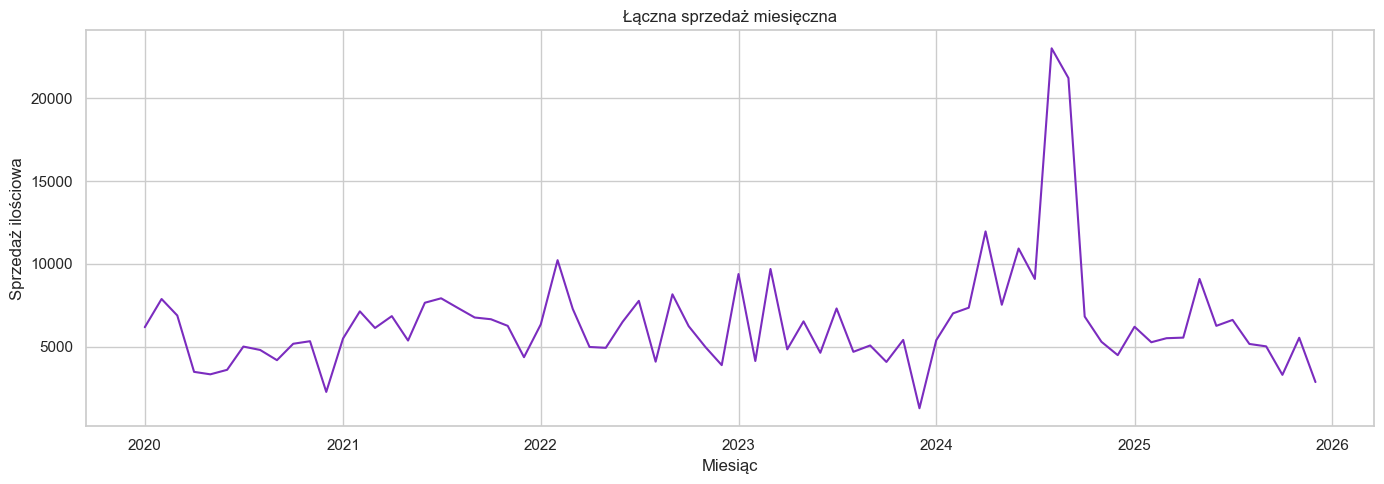

In [641]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales_global,
    x="miesiac",
    y="sprzedaz_ilosc",
    color=colors[1]
)

plt.title("Łączna sprzedaż miesięczna")
plt.xlabel("Miesiąc")
plt.ylabel("Sprzedaż ilościowa")
plt.tight_layout()
plt.show()

Następnie przeanalizowano zmiany łącznej sprzedaży w czasie. Miesięczna sprzedaż charakteryzuje się znaczną zmiennością w całym analizowanym okresie. Nie obserwuje się stabilnego poziomu sprzedaży, a poszczególne miesiące różnią się wyraźnie pod względem jej wielkości. Szczególnie wysokie wartości odnotowano w 2024 roku, kiedy wystąpiły pojedyncze, wyraźne wzrosty sprzedaży, po których następował szybki powrót do niższych poziomów.
Tego rodzaju nagłe wzrosty są charakterystyczne dla rzeczywistych danych sprzedażowych, w których pojedyncze transakcje mogą istotnie wpłynąć na wynik danego miesiąca. Przykładowo jednorazowy zakup większej liczby jednostek przez odbiorcę może powodować wyraźny wzrost sprzedaży, który nie musi powtórzyć się w kolejnych okresach. Obserwowane wahania odzwierciedlają zatem rzeczywistą specyfikę analizowanych danych.

EDA - sprzedaż miesięczna według grup

In [642]:
monthly_sales_group = (
    df_all
    .assign(miesiac=lambda x: x["data"].dt.to_period("M").dt.to_timestamp())
    .groupby(["miesiac", "grupa"], observed=True)["sprzedaz_ilosc"]
    .sum()
    .reset_index()
)

display(monthly_sales_group.head())

,miesiac,grupa,sprzedaz_ilosc
0,2020-01-01,kola_klinowe,38.00
1,2020-01-01,kola_lancuchowe,2803.00
2,2020-01-01,kola_modulowe,430.00
3,2020-01-01,kola_zebate,249.00
4,2020-01-01,lancuchy_IWIS,824.48


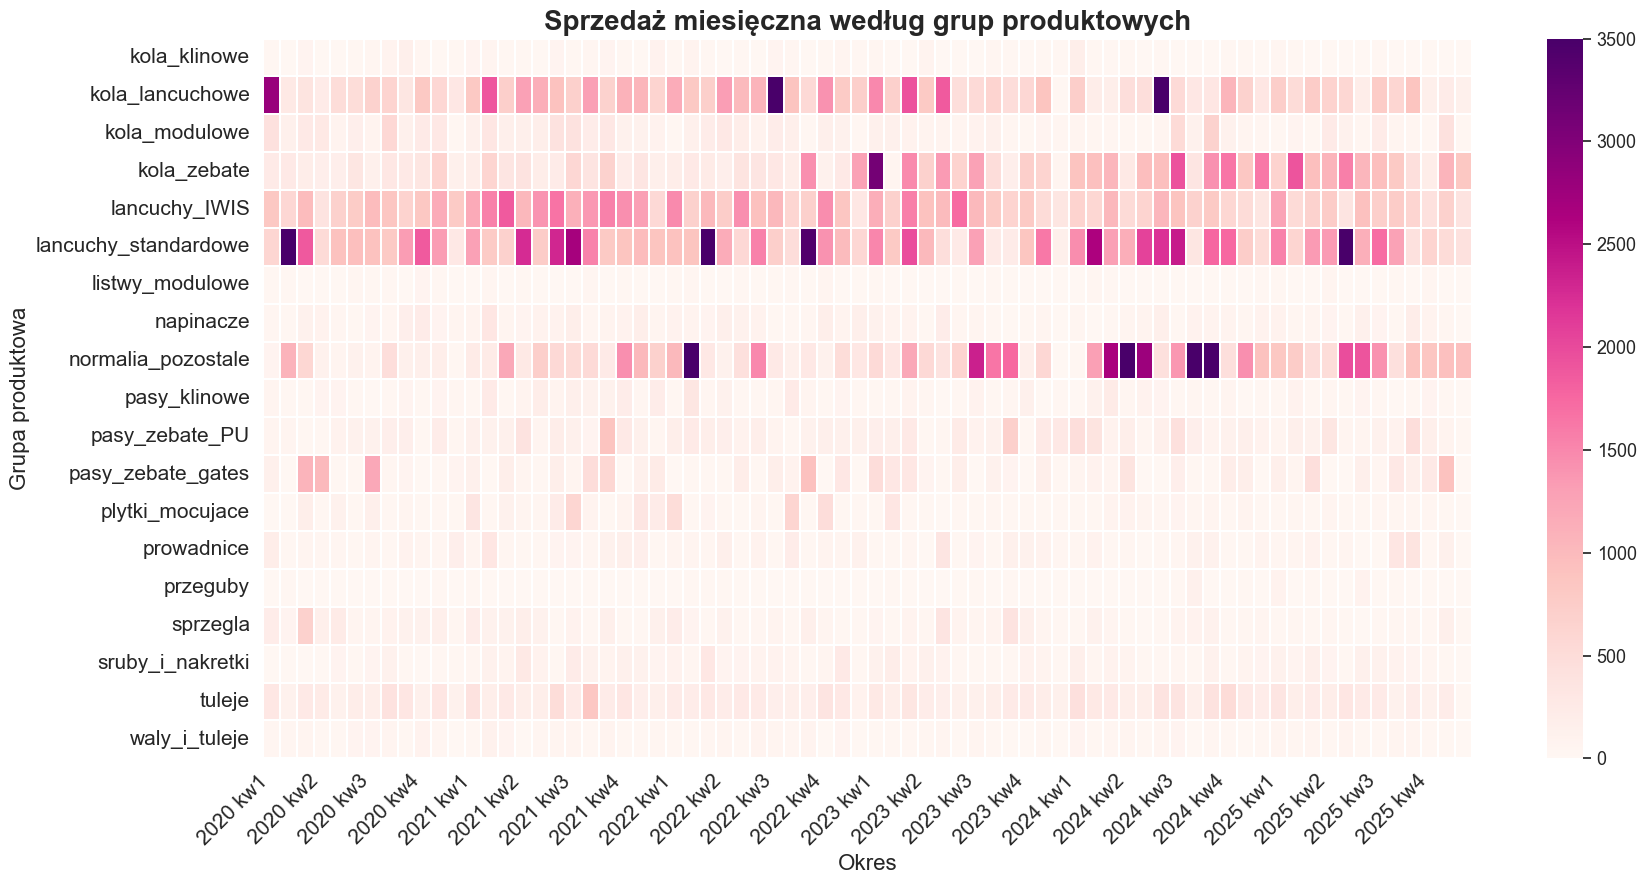

In [643]:
heatmap_data = (
    monthly_sales_group
    .pivot_table(
        index="grupa",
        columns="miesiac",
        values="sprzedaz_ilosc",
        aggfunc="sum"
    )
)

plt.figure(figsize=(18, 9))

ax = sns.heatmap(
    heatmap_data,
    cmap="RdPu",
    vmin=0,
    vmax=3500,
    linewidths=0.3,
    linecolor="white"
)

ax.collections[0].colorbar.ax.tick_params(labelsize=13)

dates = pd.to_datetime(heatmap_data.columns)
idx = np.arange(0, len(dates), 3)

plt.xticks(
    idx + 0.5,
    [f"{dates[i].year} kw{dates[i].quarter}" for i in idx],
    rotation=45,
    ha="right",
    fontsize=15
)

plt.yticks(fontsize=15)

plt.title(
    "Sprzedaż miesięczna według grup produktowych",
    fontsize=20,
    fontweight="bold"
)

plt.xlabel("Okres", fontsize=16)
plt.ylabel("Grupa produktowa", fontsize=16)

plt.tight_layout()
plt.show()

Na powyższym wykresie można zaobserwować, że wyższe poziomy miesięcznej sprzedaży występowały przede wszystkim w grupach łańcuchy standardowe, łańcuchy IWIS, normalia pozostałe, koła łańcuchowe oraz koła zębate. Jednocześnie w większości grup nie obserwuje się wyraźnie powtarzających się okresów wzmożonej sprzedaży. 
Wyjątek stanowi przede wszystkim grupa normalia pozostałe, dla której widoczna jest zdecydowanie wyższa sprzedaż w maju, wrześniu i październiku 2024 roku. W celu zwiększenia czytelności rysunku skalę kolorystyczną ograniczono do 3500 jednostek, dlatego wartości przekraczające ten poziom są przedstawione za pomocą tego samego, najciemniejszego odcienia. Ograniczenie to dotyczy wyłącznie sposobu prezentacji danych, a nie wartości uwzględnionych w analizie.


EDA - liczba aktywnych produktów w czasie

In [644]:
active_products_monthly = (
    df_all
    .assign(miesiac=lambda x: x["data"].dt.to_period("M").dt.to_timestamp())
    .groupby("miesiac", observed=True)["produkt_id"]
    .nunique()
    .reset_index(name="liczba_aktywnych_produktow")
)

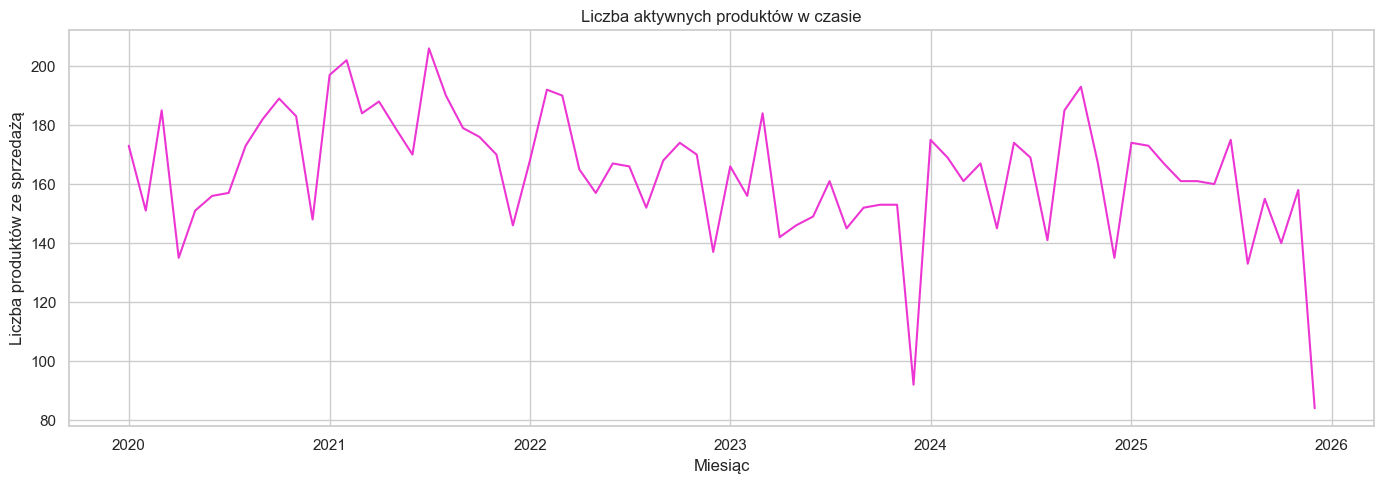

In [645]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=active_products_monthly,
    x="miesiac",
    y="liczba_aktywnych_produktow",
    color=colors[2]
)

plt.title("Liczba aktywnych produktów w czasie")
plt.xlabel("Miesiąc")
plt.ylabel("Liczba produktów ze sprzedażą")
plt.tight_layout()
plt.show()

Za produkt aktywny uznano produkt, dla którego w danym miesiącu wystąpił co najmniej jeden rekord sprzedaży. Liczba takich produktów w większości miesięcy wynosi około 140-190, przy czym okresowo w 2021 roku wzrosła do 206. Kolejną wyraźną zmianę odnotowano pod koniec 2023 roku, kiedy liczba aktywnych produktów spadła do 92. Wskazuje to, że liczba produktów generujących sprzedaż nie jest stała i zmienia się pomiędzy kolejnymi miesiącami. Szczególnie niską wartość na końcu szeregu należy jednak interpretować ostrożnie, ponieważ ostatnia obserwacja obejmuje jedynie część grudnia 2025 roku.

EDA - top produkty według sprzedaży

In [646]:
top_products_sales = (
    df_all
    .groupby(["produkt_id", "symbol_produktu", "nazwa_produktu"], observed=True)["sprzedaz_ilosc"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

display(top_products_sales)

,produkt_id,symbol_produktu,nazwa_produktu,sprzedaz_ilosc
0,MB 600-040 | Uszczelnienie Expander 4x4; korpu...,MB 600-040,Uszczelnienie Expander 4x4; korpus i kulka sta...,41000.0
1,16-T2.5/36-2F | Koło zębate ALU - obrobione,16-T2.5/36-2F,Koło zębate ALU - obrobione,24229.0
2,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,17523.0
3,88700 | Koło łańcuchowe z łożyskiem 08B1 Z18 (Z),88700,Koło łańcuchowe z łożyskiem 08B1 Z18 (Z),12382.0
4,88867 | Koło łańcuchowe z łożyskiem 10B1 Z14 (Z),88867,Koło łańcuchowe z łożyskiem 10B1 Z14 (Z),10663.0


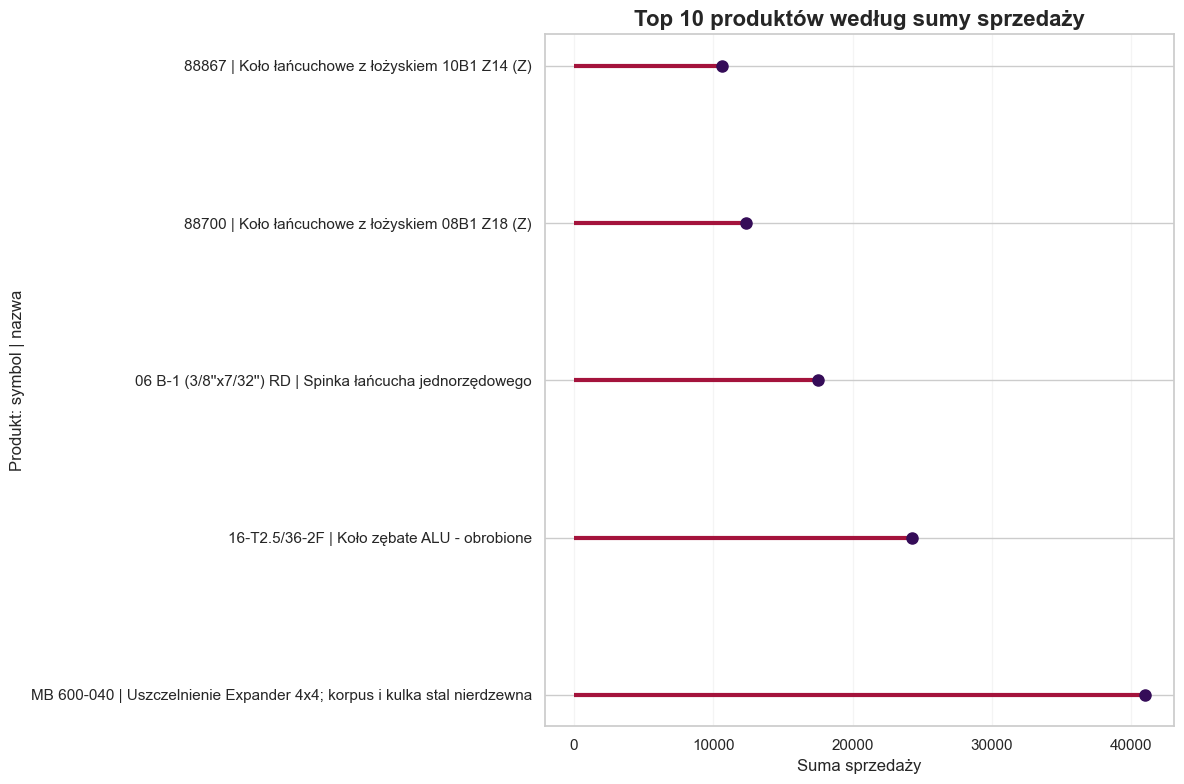

In [647]:
plt.figure(figsize=(12, 8))

plt.hlines(
    y=top_products_sales["produkt_id"],
    xmin=0,
    xmax=top_products_sales["sprzedaz_ilosc"],
    color=colors[4],
    linewidth=3
)

plt.plot(
    top_products_sales["sprzedaz_ilosc"],
    top_products_sales["produkt_id"],
    "o",
    color=colors[5],
    markersize=8
)

plt.title(
    "Top 10 produktów według sumy sprzedaży",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Suma sprzedaży")
plt.ylabel("Produkt: symbol | nazwa")

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

EDA - skumulowany udział produktów w całkowitej sprzedaży

In [648]:
product_sales_share = (
    df_all
    .groupby("produkt_id", observed=True)["sprzedaz_ilosc"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

product_sales_share["udzial"] = (
    product_sales_share["sprzedaz_ilosc"]
    / product_sales_share["sprzedaz_ilosc"].sum()
)

product_sales_share["udzial_skumulowany"] = product_sales_share["udzial"].cumsum()

display(product_sales_share.head(5))

,produkt_id,sprzedaz_ilosc,udzial,udzial_skumulowany
0,MB 600-040 | Uszczelnienie Expander 4x4; korpu...,41000.0,0.088305,0.088305
1,16-T2.5/36-2F | Koło zębate ALU - obrobione,24229.0,0.052184,0.140488
2,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,17523.0,0.037741,0.178229
3,88700 | Koło łańcuchowe z łożyskiem 08B1 Z18 (Z),12382.0,0.026668,0.204897
4,88867 | Koło łańcuchowe z łożyskiem 10B1 Z14 (Z),10663.0,0.022966,0.227862


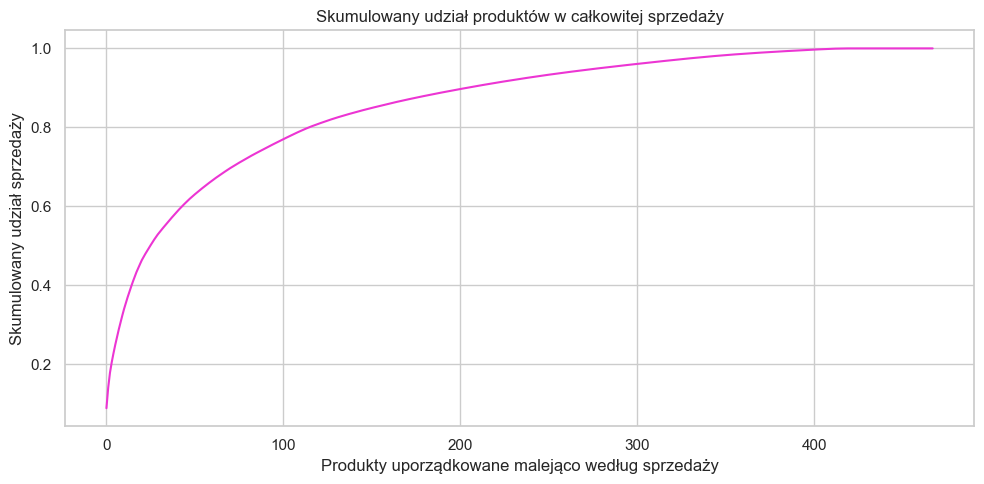

In [649]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=product_sales_share.reset_index(),
    x="index",
    y="udzial_skumulowany",
    color=colors[2]
)

plt.title("Skumulowany udział produktów w całkowitej sprzedaży")
plt.xlabel("Produkty uporządkowane malejąco według sprzedaży")
plt.ylabel("Skumulowany udział sprzedaży")
plt.tight_layout()
plt.show()

Zróżnicowanie sprzedaży pomiędzy produktami potwierdza analiza skumulowanego udziału produktów w całkowitej sprzedaży. Produkty uporządkowano malejąco według wielkości sprzedaży. Krzywa początkowo rośnie bardzo szybko, co oznacza, że stosunkowo niewielka liczba najlepiej sprzedających się produktów odpowiada za znaczną część całkowitej sprzedaży. Około 100 produktów generuje już w przybliżeniu 77% całkowitej sprzedaży, natomiast kolejne produkty zwiększają skumulowany udział coraz wolniej. Wskazuje to na nierównomierny rozkład sprzedaży pomiędzy produktami - niewielka grupa najlepiej sprzedających się produktów odpowiada za dużą część sprzedaży, podczas gdy udział kolejnych produktów jest coraz mniejszy.

Diagnoza wartości odstających

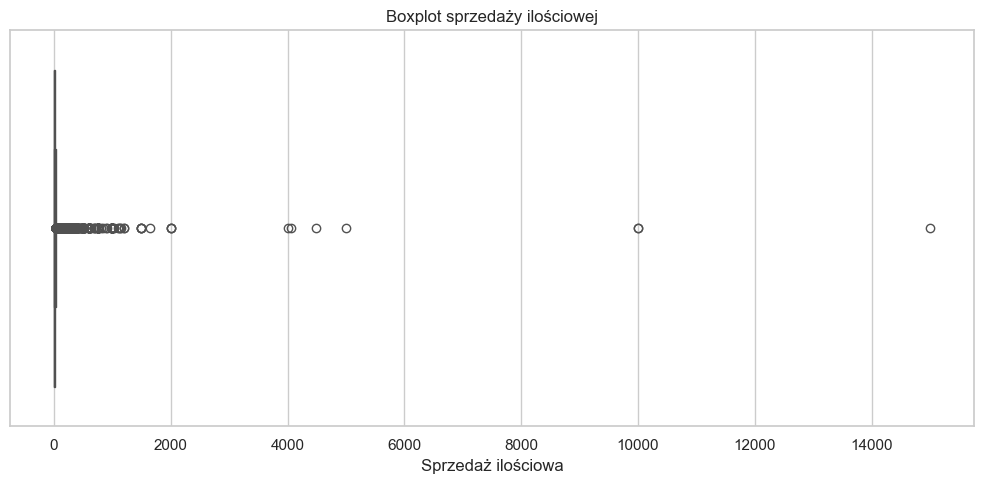

In [650]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_all,
    x="sprzedaz_ilosc",
    color=colors[3]
)

plt.title("Boxplot sprzedaży ilościowej")
plt.xlabel("Sprzedaż ilościowa")
plt.tight_layout()
plt.show()

Wcześniej zaobserwowaną asymetrię rozkładu potwierdza również wykres pudełkowy. Widoczna jest duża liczba obserwacji odstających po prawej stronie rozkładu. Większość wartości sprzedaży koncentruje się na niskim poziomie, natomiast pojedyncze obserwacje osiągają wielokrotnie wyższe wartości, sięgające około 4-5 tys., 10 tys., a nawet 15 tys. jednostek.
Obserwacje te wskazują na występowanie sporadycznych transakcji o bardzo dużej wielkości, znacząco odbiegających od typowego poziomu sprzedaży. Odzwierciedla to specyfikę rzeczywistych danych sprzedażowych, w których obok typowych, niewielkich transakcji mogą pojawiać się jednorazowe zamówienia o znacznie większej skali. Potwierdza to duże zróżnicowanie wielkości realizowanej sprzedaży.

# Pierwsza agregacja miesięczna

Służy do zbudowania miesięcznych szeregów caasowych produktów oraz wyboru produktów z liczbą miesięcy równą/większą od 40.

In [651]:
df_monthly = (
    df_all
    .assign(miesiac=lambda x: x["data"].dt.to_period("M").dt.to_timestamp())
    .groupby(
        ["produkt_id", "symbol_produktu", "nazwa_produktu", "grupa", "jednostka", "miesiac"],
        observed=True
    )["sprzedaz_ilosc"]
    .sum()
    .reset_index()
    .sort_values(["produkt_id", "miesiac"])
    .reset_index(drop=True)
)

display(df_monthly.head())
print("Shape df_monthly:", df_monthly.shape)

,produkt_id,symbol_produktu,nazwa_produktu,grupa,jednostka,miesiac,sprzedaz_ilosc
0,"1''x17,02mm | Prowadnica łańcucha rolkowego p...","1''x17,02mm",Prowadnica łańcucha rolkowego profil 1,prowadnice,m,2020-03-01,2.0
1,"1''x17,02mm | Prowadnica łańcucha rolkowego p...","1''x17,02mm",Prowadnica łańcucha rolkowego profil 1,prowadnice,m,2020-04-01,14.0
2,"1''x17,02mm | Prowadnica łańcucha rolkowego p...","1''x17,02mm",Prowadnica łańcucha rolkowego profil 1,prowadnice,m,2020-06-01,28.0
3,"1''x17,02mm | Prowadnica łańcucha rolkowego p...","1''x17,02mm",Prowadnica łańcucha rolkowego profil 1,prowadnice,m,2020-08-01,18.0
4,"1''x17,02mm | Prowadnica łańcucha rolkowego p...","1''x17,02mm",Prowadnica łańcucha rolkowego profil 1,prowadnice,m,2020-10-01,10.0


Shape df_monthly: (11797, 7)


In [652]:
series_lengths_monthly = (
    df_monthly
    .groupby("produkt_id", observed=True)
    .agg(
        symbol_produktu=("symbol_produktu", "first"),
        nazwa_produktu=("nazwa_produktu", "first"),
        grupa=("grupa", "first"),
        jednostka=("jednostka", "first"),
        pierwszy_miesiac=("miesiac", "min"),
        ostatni_miesiac=("miesiac", "max"),
        liczba_miesiecy_sprzedazy=("miesiac", "nunique"),
        suma_sprzedazy=("sprzedaz_ilosc", "sum"),
        srednia_sprzedaz=("sprzedaz_ilosc", "mean"),
        mediana_sprzedaz=("sprzedaz_ilosc", "median")
    )
    .reset_index()
    .sort_values("liczba_miesiecy_sprzedazy")
)

display(series_lengths_monthly.head(5))
display(series_lengths_monthly["liczba_miesiecy_sprzedazy"].describe())


,produkt_id,symbol_produktu,nazwa_produktu,grupa,jednostka,pierwszy_miesiac,ostatni_miesiac,liczba_miesiecy_sprzedazy,suma_sprzedazy,srednia_sprzedaz,mediana_sprzedaz
1,0.640.413.XXXX | Przegub pojedynczy z łożyskie...,0.640.413.XXXX,"Przegub pojedynczy z łożyskiem igiełkowym, S=7...",przeguby,szt,2025-06-01,2025-06-01,1,100.00,100.00,100.00
337,M16 ZN; 17X40 (E41270) | Podkładka M16; 300HV;...,M16 ZN; 17X40 (E41270),Podkładka M16; 300HV; cynkowana; DIN 7349,normalia_pozostale,szt,2022-01-01,2022-01-01,1,900.00,900.00,900.00
62,1440-8MGT4 | Pas zębaty GATES PowerGrip GT4 rękaw,1440-8MGT4,Pas zębaty GATES PowerGrip GT4 rękaw,pasy_zebate_gates,m,2025-12-01,2025-12-01,1,0.40,0.40,0.40
65,14RP-55 PAZ | Pas zębaty metraż PU,14RP-55 PAZ,Pas zębaty metraż PU,pasy_zebate_PU,m,2025-04-01,2025-04-01,1,240.00,240.00,240.00
266,"AT10-560, Z56 | Pas zębaty PU","AT10-560, Z56",Pas zębaty PU,pasy_zebate_PU,m,2023-03-01,2023-03-01,1,0.25,0.25,0.25


count    468.000000
mean      25.207265
std       18.960169
min        1.000000
25%        9.000000
50%       21.000000
75%       38.000000
max       72.000000
Name: liczba_miesiecy_sprzedazy, dtype: float64

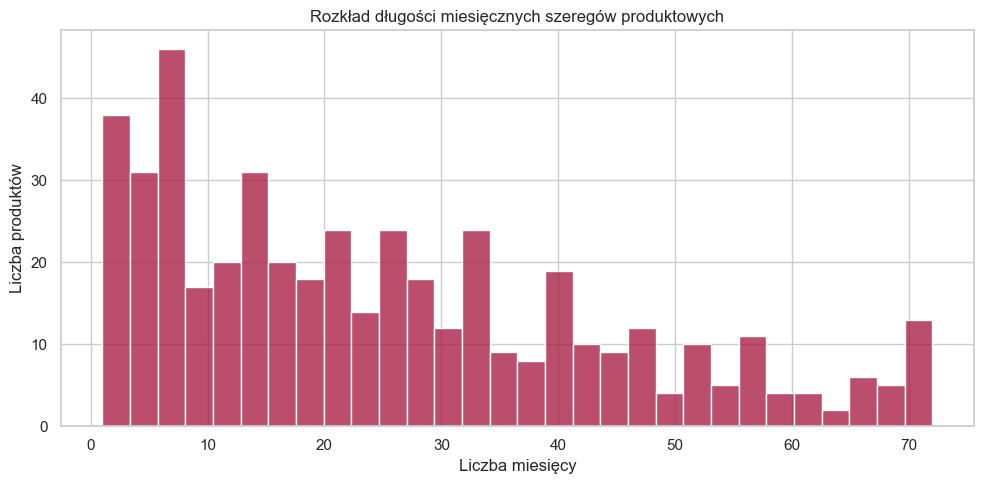

In [653]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=series_lengths_monthly,
    x="liczba_miesiecy_sprzedazy",
    bins=30,
    color=colors[4]
)

plt.title("Rozkład długości miesięcznych szeregów produktowych")
plt.xlabel("Liczba miesięcy")
plt.ylabel("Liczba produktów")
plt.tight_layout()
plt.show()

Widoczne jest duże zróżnicowanie długości szeregów - od 1 do 72 miesięcy. Najwięcej produktów charakteryzowało się stosunkowo krótkimi szeregami, obejmującymi mniej niż 30 miesięcy obserwacji, natomiast wraz ze wzrostem długości szeregu liczba produktów generalnie malała. Jednocześnie w zbiorze występowała grupa produktów posiadających znacznie dłuższą historię sprzedaży, sięgającą ponad 70 miesięcy.

In [654]:
length_bins = pd.cut(
    series_lengths_monthly["liczba_miesiecy_sprzedazy"],
    bins=[0, 3, 6, 12, 24, 36, 48, 60, 72],
    labels=[
        "1-3 mies.",
        "4-6 mies.",
        "7-12 mies.",
        "13-24 mies.",
        "25-36 mies.",
        "37-48 mies.",
        "49-60 mies.",
        "61-72 mies."
    ],
    include_lowest=True
)

length_summary = (
    length_bins
    .value_counts()
    .sort_index()
    .to_frame("liczba_produktow")
)

length_summary["udzial_%"] = round(
    length_summary["liczba_produktow"]
    / length_summary["liczba_produktow"].sum()
    * 100, 2
)

display(length_summary)

,liczba_produktow,udzial_%
liczba_miesiecy_sprzedazy,,
1-3 mies.,38,8.12
4-6 mies.,45,9.62
7-12 mies.,69,14.74
13-24 mies.,107,22.86
25-36 mies.,87,18.59
37-48 mies.,58,12.39
49-60 mies.,34,7.26
61-72 mies.,30,6.41


# EDA miesięcznych szeregów sprzedaży

In [655]:
monthly_summary = (
    df_monthly
    .groupby("produkt_id", observed=True)
    .agg(
        liczba_miesiecy_sprzedazy=("miesiac", "nunique"),
        suma_sprzedazy=("sprzedaz_ilosc", "sum"),
        srednia_sprzedaz=("sprzedaz_ilosc", "mean"),
        mediana_sprzedaz=("sprzedaz_ilosc", "median"),
        pierwszy_miesiac=("miesiac", "min"),
        ostatni_miesiac=("miesiac", "max"),
        grupa=("grupa", "first"),
        jednostka=("jednostka", "first")
    )
    .sort_values("liczba_miesiecy_sprzedazy")
)

Wykres miesicy z 0

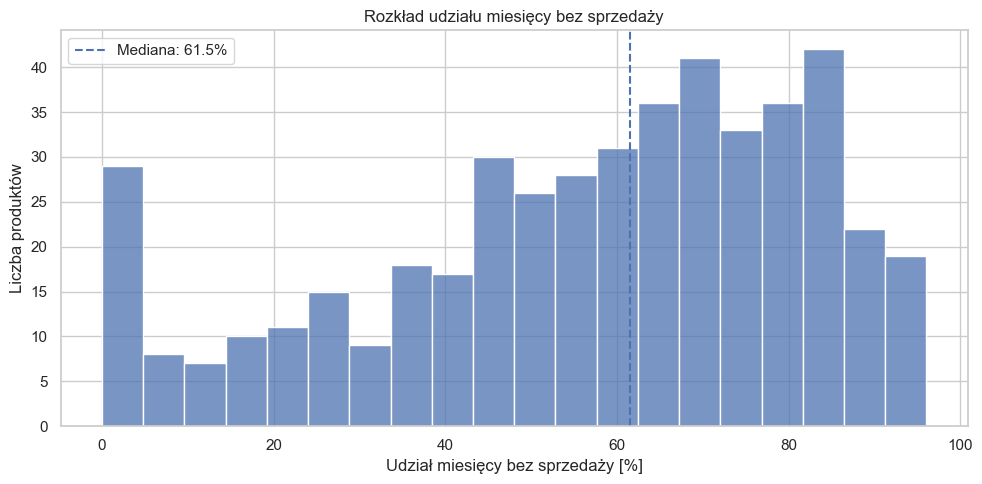

In [656]:
df_mth_zero = (
    df_monthly.set_index("miesiac")
    .groupby("produkt_id")["sprzedaz_ilosc"]
    .apply(lambda x: x.reindex(
        pd.date_range(x.index.min(), x.index.max(), freq="MS"), fill_value=0
    ))
    .rename_axis(["produkt_id", "miesiac"])
    .reset_index()
)

# Udział miesięcy bez sprzedaży
zero_share = (
    df_mth_zero.groupby("produkt_id")["sprzedaz_ilosc"]
    .apply(lambda x: (x == 0).mean() * 100)
    .rename("udzial_zero_%")
    .reset_index()
)


mediana = zero_share["udzial_zero_%"].median()

plt.figure(figsize=(10, 5))
sns.histplot(data=zero_share, x="udzial_zero_%", bins=20)
plt.axvline(mediana, linestyle="--", label=f"Mediana: {mediana:.1f}%")
plt.xlabel("Udział miesięcy bez sprzedaży [%]")
plt.ylabel("Liczba produktów")
plt.title("Rozkład udziału miesięcy bez sprzedaży")
plt.legend()
plt.tight_layout()
plt.show()

Udział miesięcy bez sprzedaży był silnie zróżnicowany pomiędzy produktami i obejmował niemal cały zakres od 0% do ponad 90%. Mediana wyniosła 61,5%, co oznacza, że dla połowy produktów miesiące bez sprzedaży stanowiły co najmniej 61,5% okresu pomiędzy pierwszym a ostatnim wystąpieniem produktu. Widoczna koncentracja obserwacji przy wysokich wartościach tego wskaźnika potwierdza wysoki stopień nieregularności sprzedaży oraz częste występowanie miesięcy bez odnotowanej transakcji. Wynik ten stanowi istotne uzasadnienie dla zastosowania w dalszej części badania metod przeznaczonych do prognozowania sprzedaży nieregularnej.

# Przygotowanie zbioru modelowego



In [657]:
min_sales_months = 40

valid_products = monthly_summary[
    monthly_summary["liczba_miesiecy_sprzedazy"] >= min_sales_months
].index

df_model = df_monthly[
    df_monthly["produkt_id"].isin(valid_products)
].copy()

display(df_model.head())

,produkt_id,symbol_produktu,nazwa_produktu,grupa,jednostka,miesiac,sprzedaz_ilosc
26,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,2020-01-01,43.0
27,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,2020-02-01,10.0
28,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,2020-03-01,436.0
29,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,2020-04-01,25.0
30,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,2020-05-01,57.0


In [658]:
print("Liczba produktów przed filtrowaniem:", df_monthly["produkt_id"].nunique())
print("Liczba produktów po filtrowaniu:", df_model["produkt_id"].nunique())
print("Liczba obserwacji po filtrowaniu:", len(df_model))

Liczba produktów przed filtrowaniem: 468
Liczba produktów po filtrowaniu: 105
Liczba obserwacji po filtrowaniu: 5673


Na potrzeby modelowania ograniczono zbiór danych do produktów posiadających odpowiednio długą historię sprzedaży (minimalnie 40 miesięcy). Celem tego ograniczenia było zapewnienie wystarczającej liczby obserwacji do budowy i oceny modeli prognostycznych. Produkty o krótszej historii sprzedaży zostały pominięte, ponieważ ich szeregi czasowe mogłyby prowadzić do niestabilnych i mało wiarygodnych prognoz.

In [659]:
model_summary = (
    df_model
    .groupby("produkt_id", observed=True)
    .agg(
        liczba_miesiecy_sprzedazy=("miesiac", "nunique"),
        suma_sprzedazy=("sprzedaz_ilosc", "sum"),
        srednia_sprzedaz=("sprzedaz_ilosc", "mean"),
        mediana_sprzedaz=("sprzedaz_ilosc", "median"),
        pierwszy_miesiac=("miesiac", "min"),
        ostatni_miesiac=("miesiac", "max"),
        grupa=("grupa", "first"),
        jednostka=("jednostka", "first")
    )
)

display(model_summary.describe())
display(model_summary["grupa"].value_counts())

,liczba_miesiecy_sprzedazy,suma_sprzedazy,srednia_sprzedaz,mediana_sprzedaz,pierwszy_miesiac,ostatni_miesiac
count,105.000000,105.000000,105.000000,105.000000,105,105
mean,54.028571,1808.030857,29.365538,18.078571,2020-01-18 17:22:17.142857216,2025-11-03 07:46:17.142857216
min,40.000000,195.000000,3.338710,2.000000,2020-01-01 00:00:00,2025-03-01 00:00:00
25%,45.000000,370.140000,7.813953,4.500000,2020-01-01 00:00:00,2025-11-01 00:00:00
50%,53.000000,733.000000,15.593143,9.000000,2020-01-01 00:00:00,2025-11-01 00:00:00
75%,62.000000,1879.000000,31.242857,20.000000,2020-01-01 00:00:00,2025-12-01 00:00:00
max,72.000000,17523.000000,261.537313,142.000000,2021-02-01 00:00:00,2025-12-01 00:00:00
std,10.267066,2739.456081,39.396571,23.907802,NaN,NaN


grupa
tuleje                  23
lancuchy_IWIS           21
lancuchy_standardowe    16
kola_zebate              8
napinacze                7
kola_lancuchowe          7
waly_i_tuleje            6
sruby_i_nakretki         4
plytki_mocujace          3
pasy_klinowe             2
kola_modulowe            2
pasy_zebate_gates        1
pasy_zebate_PU           1
listwy_modulowe          1
normalia_pozostale       1
sprzegla                 1
prowadnice               1
kola_klinowe             0
przeguby                 0
Name: count, dtype: int64

# Chronologiczny podział 80/20

Pierwsze ok. 80% obserwacji danego produktu przypisano do zbioru treningowego, natomiast ostatnie ok. 20% obserwacji do zbioru testowego. Podział wykonano osobno dla każdego produktu, bez losowego mieszania obserwacji, dzięki czemu zachowano naturalny porządek czasowy danych.

In [660]:
df_model = df_model.sort_values(["produkt_id", "miesiac"]).copy()

df_model["nr_miesiaca"] = (
    df_model
    .groupby("produkt_id", observed=True)
    .cumcount() + 1
)

df_model["liczba_miesiecy"] = (
    df_model
    .groupby("produkt_id", observed=True)["miesiac"]
    .transform("count")
)

df_model["liczba_test"] = np.ceil(
    df_model["liczba_miesiecy"] * 0.2
).astype(int)

df_model["liczba_train"] = (
    df_model["liczba_miesiecy"] - df_model["liczba_test"]
)

df_model["zbior"] = np.where(
    df_model["nr_miesiaca"] <= df_model["liczba_train"],
    "train",
    "test"
)

train = df_model[df_model["zbior"] == "train"].copy()
test = df_model[df_model["zbior"] == "test"].copy()

print("Train shape:", train.shape, "\nLiczba produktów train:", train["produkt_id"].nunique())
print("Test shape:", test.shape, "\nLiczba produktów test:", test["produkt_id"].nunique())

Train shape: (4493, 12) 
Liczba produktów train: 105
Test shape: (1180, 12) 
Liczba produktów test: 105


# Winsoryzacja na danych transakcyjnych

Po ustaleniu podziału danych na zbiór treningowy i testowy w proporcji 80/20 przeprowadzono winsoryzację danych transakcyjnych. Progi winsoryzacji wyznaczono wyłącznie na podstawie zbioru treningowego, aby zapobiec wyciekowi informacji ze zbioru testowego osobno dla każdej grupy produktowej.

In [661]:
koniec_train = (
    train
    .groupby("produkt_id", observed=True)["miesiac"]
    .max()
)

# surowe dane - sprzed winsoryzacji
df_winsor = df_all[
    df_all["produkt_id"].isin(df_model["produkt_id"].unique())
].copy()

df_winsor["miesiac"] = (
    df_winsor["data"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

df_winsor["koniec_train"] = (
    df_winsor["produkt_id"].map(koniec_train)
)

df_winsor["zbior"] = np.where(
    df_winsor["miesiac"] <= df_winsor["koniec_train"],
    "train",
    "test"
)

# q99 liczony tylko z części treningowej
q99_train = (
    df_winsor[df_winsor["zbior"] == "train"]
    .groupby("grupa", observed=True)["sprzedaz_ilosc"]
    .quantile(0.99)
)

df_winsor["limit_99"] = (
    df_winsor["grupa"].map(q99_train)
)

# ten sam próg wyznaczony na TRAIN do danych
df_winsor["sprzedaz_ilosc_winsor"] = np.where(
    df_winsor["limit_99"].notna(),
    np.minimum(
        df_winsor["sprzedaz_ilosc"],
        df_winsor["limit_99"]
    ),
    df_winsor["sprzedaz_ilosc"]
)

# Ponowna agregacja miesięczna

Wykonuje się ponowną agregację miesięczną, ale już sprzedaży po winsoryzacji

Liczba wartości przyciętych: 113
Łączna wartość redukcji: 17135.82


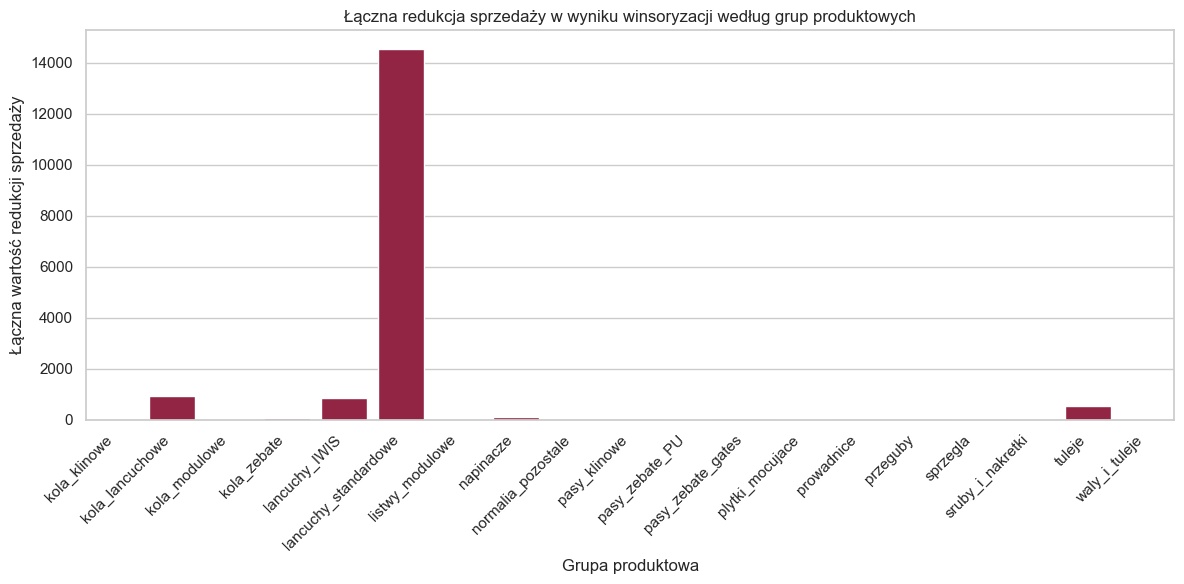

In [662]:
# Agregacja miesięczna po winsoryzacji
sprzedaz_monthly_winsor = (
    df_winsor.groupby(["produkt_id", "miesiac"], observed=True)["sprzedaz_ilosc_winsor"]
    .sum()
    .reset_index(name="sprzedaz_ilosc")
)

df_model = (
    df_model.drop(columns="sprzedaz_ilosc")
    .merge(sprzedaz_monthly_winsor, on=["produkt_id", "miesiac"], how="left")
)

# Efekt winsoryzacji
df_przyciete = (
    df_winsor.assign(
        roznica=df_winsor["sprzedaz_ilosc"] - df_winsor["sprzedaz_ilosc_winsor"]
    )
    .query("roznica > 0")
)

print("Liczba wartości przyciętych:", len(df_przyciete))
print("Łączna wartość redukcji:", round(df_przyciete["roznica"].sum(), 2))

# Redukcja według grup
winsor_reduction_group = (
    df_przyciete.groupby("grupa", observed=True)["roznica"]
    .agg(
        liczba_przycietych="size",
        suma_redukcji="sum",
        srednia_redukcja="mean",
        max_redukcja="max"
    )
    .reset_index()
    .sort_values("suma_redukcji", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(data=winsor_reduction_group, x="grupa", y="suma_redukcji", color=colors[4])
plt.title("Łączna redukcja sprzedaży w wyniku winsoryzacji według grup produktowych")
plt.xlabel("Grupa produktowa")
plt.ylabel("Łączna wartość redukcji sprzedaży")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

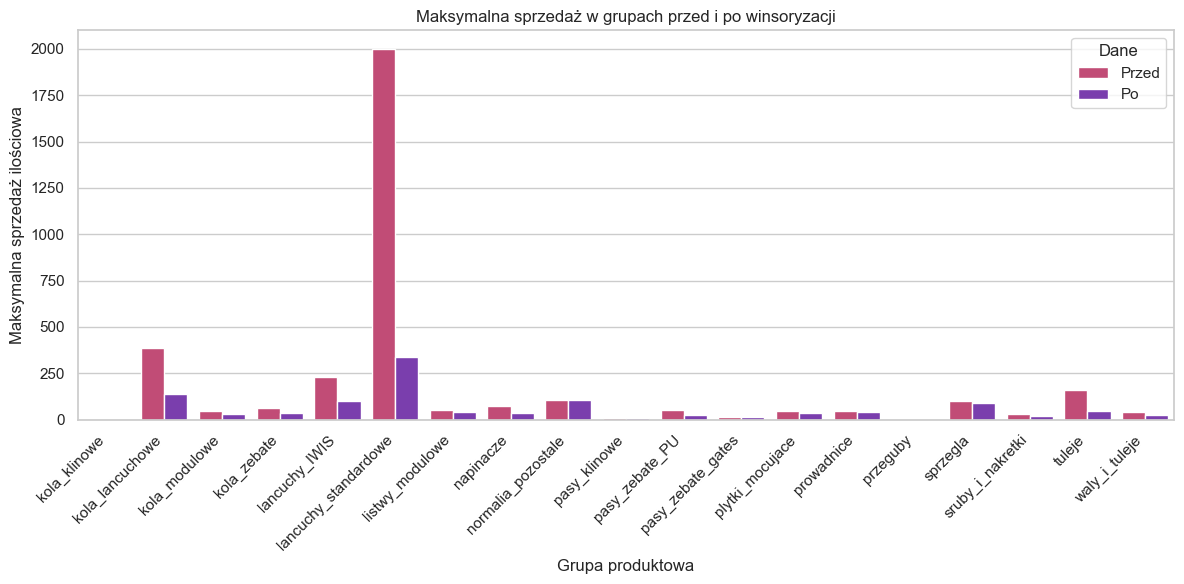

In [663]:
max_before_after = (
    df_winsor.groupby("grupa", observed=True)
    .agg(
        Przed=("sprzedaz_ilosc", "max"),
        Po=("sprzedaz_ilosc_winsor", "max")
    )
    .reset_index()
    .melt("grupa", var_name="wariant", value_name="maksymalna_sprzedaz")
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=max_before_after,
    x="grupa",
    y="maksymalna_sprzedaz",
    hue="wariant",
    palette=[colors[3], colors[1]]
)

plt.title("Maksymalna sprzedaż w grupach przed i po winsoryzacji")
plt.xlabel("Grupa produktowa")
plt.ylabel("Maksymalna sprzedaż ilościowa")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Dane")
plt.tight_layout()
plt.show()

In [664]:
tabela_max = (
    max_before_after_group
    .assign(
        roznica=lambda x: x["max_przed"] - x["max_po"],
        redukcja_proc=lambda x: (x["max_przed"] - x["max_po"]) / x["max_przed"] * 100
    )
    .round(2)
)

display(tabela_max)

,grupa,max_przed,max_po,roznica,redukcja_proc
0,kola_lancuchowe,385.00,138.38,246.62,64.06
1,kola_modulowe,44.00,32.00,12.00,27.27
2,kola_zebate,64.00,35.88,28.12,43.94
3,lancuchy_IWIS,230.00,100.00,130.00,56.52
4,lancuchy_standardowe,2000.00,336.27,1663.73,83.19
5,listwy_modulowe,50.52,40.00,10.52,20.82
6,napinacze,72.00,36.50,35.50,49.31
7,normalia_pozostale,106.00,103.30,2.70,2.55
8,pasy_klinowe,10.00,9.44,0.56,5.60
9,pasy_zebate_PU,52.95,27.32,25.63,48.40


Zachowuje się wcześniej ustalone przypisanie miesięcy do train/test. W kodzie ponownie tworzy się obiekty train i test, ale tylko z już poprawionych wartości sprzedaży.

In [665]:
train = df_model[df_model["zbior"] == "train"].copy()
test = df_model[df_model["zbior"] == "test"].copy()

print("Train shape:", train.shape)
print("Test shape:", test.shape)

display(q99_train)

print("Liczba braków:")
print(df_model["sprzedaz_ilosc"].isna().sum())

Train shape: (4493, 12)
Test shape: (1180, 12)


grupa
kola_lancuchowe         138.380
kola_modulowe            32.000
kola_zebate              35.880
lancuchy_IWIS           100.000
lancuchy_standardowe    336.270
listwy_modulowe          40.000
napinacze                36.500
normalia_pozostale      103.300
pasy_klinowe              9.440
pasy_zebate_PU           27.321
pasy_zebate_gates        15.000
plytki_mocujace          33.100
prowadnice               42.280
sprzegla                 90.100
sruby_i_nakretki         20.310
tuleje                   45.190
waly_i_tuleje            26.190
Name: sprzedaz_ilosc, dtype: float64

Liczba braków:
0


In [666]:
split_check = (
    df_model
    .groupby(["produkt_id", "zbior"], observed=True)["miesiac"]
    .nunique()
    .unstack(fill_value=0)
)

split_check["razem"] = split_check["train"] + split_check["test"]
split_check["udzial_test"] = split_check["test"] / split_check["razem"]

display(split_check.head())
display(split_check.describe())

zbior,test,train,razem,udzial_test
produkt_id,,,,
06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jednorzędowego,14,53,67,0.208955
06 B-1 (3/8''x7/32'') RD | Łańcuch rolkowy jednorzędowy,14,53,67,0.208955
06 B-1 (3/8''x7/32'') | Spinka łańcuchowa IWIS,14,55,69,0.202899
06 B-1 (3/8''x7/32'') | Łańcuch rolkowy IWIS,14,53,67,0.208955
08 B-1 (1/2''x5/16'') | Spinka redukcyjna,12,45,57,0.210526


zbior,test,train,razem,udzial_test
count,105.000000,105.000000,105.000000,105.000000
mean,11.238095,42.790476,54.028571,0.208111
std,2.114619,8.176767,10.267066,0.005562
min,8.000000,32.000000,40.000000,0.200000
25%,9.000000,36.000000,45.000000,0.203704
50%,11.000000,42.000000,53.000000,0.208955
75%,13.000000,49.000000,62.000000,0.212766
max,15.000000,57.000000,72.000000,0.219512


Sprawdzono poprawność podziału danych na zbiory treningowy i testowy. Dla każdego produktu wyznaczono liczbę miesięcy przypisanych do części treningowej i testowej oraz obliczono udział obserwacji testowych w całym szeregu. Kontrola potwierdziła, że każdy produkt posiada zarówno część treningową, jak i testową.

In [667]:
print("Minimalna liczba miesięcy testowych:", split_check["test"].min())
print("Minimalna liczba miesięcy treningowych:", split_check["train"].min())

print("Maksymalna liczba miesięcy testowych:", split_check["test"].max())
print("Maksymalna liczba miesięcy treningowych:", split_check["train"].max())

Minimalna liczba miesięcy testowych: 8
Minimalna liczba miesięcy treningowych: 32
Maksymalna liczba miesięcy testowych: 15
Maksymalna liczba miesięcy treningowych: 57


In [668]:
print("Przed:", df_all["sprzedaz_ilosc"].sum())
print("Po:", df_monthly["sprzedaz_ilosc"].sum())
print("Różnica:", df_all["sprzedaz_ilosc"].sum() - df_monthly["sprzedaz_ilosc"].sum())

Przed: 464302.08978
Po: 464302.08978000004
Różnica: -5.820766091346741e-11


# Miary oceny jakości prognoz

W tej części zdefiniowano funkcje służące do oceny jakości prognoz. Funkcja 'calculate_metrics()' oblicza podstawowe miary błędu: MAE, RMSE, sMAPE oraz MASE. Miara MASE liczona jest względem błędu modelu benchmarkowego (modelu naiwnego na pełnym panelu miesiecznym z 0), dzięki czemu możliwe jest porównanie jakości prognoz między produktami o różnej skali sprzedaży.

Funkcja 'evaluate_forecasts()' wyznacza miary błędu osobno dla każdego modelu i produktu, a następnie agreguje wyniki do poziomu modelu. Dzięki temu możliwe jest porównanie skuteczności wszystkich metod prognostycznych na wspólnej podstawie.

In [669]:
def calculate_metrics(y_true, y_pred, benchmark_mae):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))

    smape = np.mean(
        2 * np.abs(y_true - y_pred) /
        (np.abs(y_true) + np.abs(y_pred) + 1e-8)
    ) * 100

    mase = mae / benchmark_mae if benchmark_mae != 0 and not np.isnan(benchmark_mae) else np.nan

    return pd.Series({
        "mae": mae,
        "rmse": rmse,
        "smape": smape,
        "mase": mase
    })

In [670]:
def evaluate_forecasts(all_forecasts, benchmark_mae_by_product):
    all_forecasts = all_forecasts.merge(
        benchmark_mae_by_product,
        on="produkt_id",
        how="left"
    )

    metrics_product = (
        all_forecasts
        .groupby(["model", "produkt_id"], observed=True)
        .apply(lambda x: calculate_metrics(
            y_true=x["y_true"],
            y_pred=x["y_pred"],
            benchmark_mae=x["benchmark_mae"].iloc[0]
        ))
        .reset_index()
    )

    results_table = (
        metrics_product
        .groupby("model", observed=True)
        .agg(
            mae=("mae", "mean"),
            rmse=("rmse", "mean"),
            smape=("smape", "mean"),
            mase=("mase", "mean"),
            mase_mediana=("mase", "median")
        )
        .sort_values("mase")
        .reset_index()
    )

    return metrics_product, results_table

In [671]:
model_labels = {
    "naiwna": "Metoda naiwna",
    "srednia_kroczaca_3": "Średnia krocząca 3M",
    "croston": "Croston",
    "sba": "SBA",
    "tsb": "TSB",
    "naiwna_panel_zero": "Naiwna - pełny panel miesięczny",
    "lgbm_classifier_ridge": "Klasyfikator LGBM + regresja Ridge",
    "lgbm_classifier_random_forest": "Klasyfikator LGBM + las losowy",
    "lgbm_classifier_lgbm_regressor": "Klasyfikator LGBM + regresor LGBM",
    "lgbm_classifier_naive": "Klasyfikator LGBM + metoda naiwna"
}

model_colors = {
    "naiwna": colors[0],
    "srednia_kroczaca_3": colors[1],
    "croston": colors[2],
    "sba": colors[3],
    "tsb": colors[4],
    "naiwna_panel_zero": colors[8],
    "lgbm_classifier_ridge": colors[5],
    "lgbm_classifier_random_forest": colors[6],
    "lgbm_classifier_lgbm_regressor": colors[7],
    "lgbm_classifier_naive": colors[9]
}

model_palette = {
    model_labels[model]: color
    for model, color in model_colors.items()
}

metric_labels = {
    "mae": "MAE",
    "rmse": "RMSE",
    "smape": "sMAPE",
    "mase": "MASE",
    "mase_mediana": "Mediana MASE"
}

In [672]:
local_models = ["naiwna", "naiwna_panel_zero", "srednia_kroczaca_3", "croston", "sba", "tsb"]

local_models_no_naive = ["srednia_kroczaca_3", "croston", "sba", "tsb", "naiwna_panel_zero"]

global_models = [
    "lgbm_classifier_ridge",
    "lgbm_classifier_random_forest",
    "lgbm_classifier_lgbm_regressor",
    "lgbm_classifier_naive"
]

# Prognozowanie

W badaniu zastosowano dwie grupy metod prognostycznych: **modele lokalne oraz modele globalne**. Modele lokalne budowane były osobno dla każdego produktu, natomiast modele globalne wykorzystywały wspólny zbiór danych obejmujący wszystkie produkty.

# Modele lokalne

Wśród modeli lokalnych uwzględniono metodę naiwną, średnią kroczącą z trzech ostatnich obserwacji oraz metody przeznaczone dla popytu nieregularnego: Croston, SBA i TSB. Metoda naiwna została potraktowana jako model benchmarkowy, czyli punkt odniesienia dla oceny pozostałych metod.

## Model naiwny uczony na panelu dodatnich wartości sprzedaży

In [673]:
last_train_values = (
    train
    .sort_values(["produkt_id", "miesiac"])
    .groupby("produkt_id", observed=True)
    .tail(1)
    [["produkt_id", "sprzedaz_ilosc"]]
    .rename(columns={"sprzedaz_ilosc": "y_pred"})
)

naive_forecast = (
    test[["produkt_id", "miesiac", "sprzedaz_ilosc", "grupa"]]
    .merge(last_train_values, on="produkt_id", how="left")
    .rename(columns={"sprzedaz_ilosc": "y_true"})
)

naive_forecast["model"] = "naiwna"

naive_forecast = naive_forecast[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred"]
]

display(naive_forecast.head())

,model,produkt_id,grupa,miesiac,y_true,y_pred
0,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,2.0
1,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,2.0
2,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,2.0
3,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,2.0
4,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,2.0


# Metoda naiwna uczona na pełnym panelu (z zerami)

In [674]:
first_test_month = (
    test
    .groupby("produkt_id", observed=True)["miesiac"]
    .min()
)

# Panel treningowy z miesiącami bez sprzedaży uzupełnionymi zerami
train_zero_panels = []

for produkt_id, df_temp in train.groupby("produkt_id", observed=True):

    months = pd.date_range(
        start=df_temp["miesiac"].min(),
        end=first_test_month.loc[produkt_id] - pd.offsets.MonthBegin(1),
        freq="MS"
    )

    panel = pd.DataFrame({
        "produkt_id": produkt_id,
        "miesiac": months
    })

    panel = panel.merge(
        df_temp[["produkt_id", "miesiac", "sprzedaz_ilosc"]],
        on=["produkt_id", "miesiac"],
        how="left"
    )

    panel["sprzedaz_ilosc"] = panel["sprzedaz_ilosc"].fillna(0)

    train_zero_panels.append(panel)

train_zero_panel = pd.concat(train_zero_panels, ignore_index=True)

last_train_zero_values = (
    train_zero_panel
    .sort_values(["produkt_id", "miesiac"])
    .groupby("produkt_id", observed=True)
    .tail(1)
    [["produkt_id", "sprzedaz_ilosc"]]
    .rename(columns={"sprzedaz_ilosc": "y_pred"})
)

# Prognoza na tym samym zbiorze testowym co pozostałe modele
naive_zero_forecast = (
    test[["produkt_id", "grupa", "miesiac", "sprzedaz_ilosc"]]
    .merge(last_train_zero_values, on="produkt_id", how="left")
    .rename(columns={"sprzedaz_ilosc": "y_true"})
)

naive_zero_forecast["model"] = "naiwna_panel_zero"

naive_zero_forecast = naive_zero_forecast[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred"]
]

display(naive_zero_forecast.head())

print("Liczba prognoz:", len(naive_zero_forecast))
print("Liczba produktów:", naive_zero_forecast["produkt_id"].nunique())
print("Braki w prognozie:", naive_zero_forecast["y_pred"].isna().sum())

,model,produkt_id,grupa,miesiac,y_true,y_pred
0,naiwna_panel_zero,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,2.0
1,naiwna_panel_zero,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,2.0
2,naiwna_panel_zero,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,2.0
3,naiwna_panel_zero,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,2.0
4,naiwna_panel_zero,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,2.0


Liczba prognoz: 1180
Liczba produktów: 105
Braki w prognozie: 0


Benchmark do MASE

Od razu po metodzie naiwnej liczony jest jej błąd MAE dla każdego produktu (mianownik do MASE dla wszystkich modeli)

In [675]:
benchmark_mae_by_product = (
    naive_zero_forecast
    .groupby("produkt_id", observed=True)
    .apply(lambda x: np.mean(np.abs(x["y_true"] - x["y_pred"])))
    .reset_index(name="benchmark_mae")
)

display(benchmark_mae_by_product.head())

,produkt_id,benchmark_mae
0,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,88.057857
1,06 B-1 (3/8''x7/32'') RD | Łańcuch rolkowy jed...,38.282143
2,06 B-1 (3/8''x7/32'') | Spinka łańcuchowa IWIS,79.142857
3,06 B-1 (3/8''x7/32'') | Łańcuch rolkowy IWIS,6.849286
4,08 B-1 (1/2''x5/16'') | Spinka redukcyjna,64.666667


## Średnia krocząca dla 3 okien

In [676]:
window = 3

moving_average_values = (
    train
    .sort_values(["produkt_id", "miesiac"])
    .groupby("produkt_id", observed=True)
    .tail(window)
    .groupby("produkt_id", observed=True)["sprzedaz_ilosc"]
    .mean()
    .reset_index(name="y_pred")
)

moving_average_forecast = (
    test[["produkt_id", "grupa", "miesiac", "sprzedaz_ilosc"]]
    .merge(moving_average_values, on="produkt_id", how="left")
    .rename(columns={"sprzedaz_ilosc": "y_true"})
)

moving_average_forecast["model"] = "srednia_kroczaca_3"

moving_average_forecast = moving_average_forecast[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred"]
]

display(moving_average_forecast.head())

print("Liczba prognoz średniej kroczącej:", len(moving_average_forecast))
print("Liczba produktów:", moving_average_forecast["produkt_id"].nunique())
print("Braki w prognozie:", moving_average_forecast["y_pred"].isna().sum())

,model,produkt_id,grupa,miesiac,y_true,y_pred
0,srednia_kroczaca_3,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,18.0
1,srednia_kroczaca_3,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,18.0
2,srednia_kroczaca_3,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,18.0
3,srednia_kroczaca_3,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,18.0
4,srednia_kroczaca_3,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,18.0


Liczba prognoz średniej kroczącej: 1180
Liczba produktów: 105
Braki w prognozie: 0


## Model Croston

In [677]:
alpha = 0.15
beta = 0.15

In [678]:
def croston_forecast_value(df_product, alpha=alpha):
    df_product = df_product.sort_values("miesiac").copy()

    y = df_product["sprzedaz_ilosc"].astype(float).values

    month_number = (
        df_product["miesiac"].dt.year * 12
        + df_product["miesiac"].dt.month
    )

    intervals = (
        month_number
        .diff()
        .fillna(1)
        .astype(int)
        .values
    )

    demand_level = y[0]
    interval_level = intervals[0]

    for demand, interval in zip(y[1:], intervals[1:]):
        demand_level = alpha * demand + (1 - alpha) * demand_level
        interval_level = alpha * interval + (1 - alpha) * interval_level

    forecast = demand_level / interval_level

    return max(forecast, 0)

In [679]:
croston_values = []

for produkt_id, df_temp in train.groupby("produkt_id", observed=True):
    y_pred = croston_forecast_value(df_temp, alpha=alpha)

    croston_values.append({
        "produkt_id": produkt_id,
        "y_pred": y_pred
    })

croston_values = pd.DataFrame(croston_values)

In [680]:
croston_forecast = (
    test[["produkt_id", "grupa", "miesiac", "sprzedaz_ilosc"]]
    .merge(croston_values, on="produkt_id", how="left")
    .rename(columns={"sprzedaz_ilosc": "y_true"})
)

croston_forecast["model"] = "croston"

croston_forecast = croston_forecast[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred"]
]

display(croston_forecast.head())

,model,produkt_id,grupa,miesiac,y_true,y_pred
0,croston,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,85.574042
1,croston,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,85.574042
2,croston,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,85.574042
3,croston,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,85.574042
4,croston,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,85.574042


## Model Syntetos and Boylan (SBA)

In [681]:
def sba_forecast_value(df_product, alpha=alpha):
    df_product = df_product.sort_values("miesiac").copy()

    y = df_product["sprzedaz_ilosc"].astype(float).values

    month_number = (
        df_product["miesiac"].dt.year * 12
        + df_product["miesiac"].dt.month
    )

    intervals = (
        month_number
        .diff()
        .fillna(1)
        .astype(int)
        .values
    )

    demand_level = y[0]
    interval_level = intervals[0]

    for demand, interval in zip(y[1:], intervals[1:]):
        demand_level = alpha * demand + (1 - alpha) * demand_level
        interval_level = alpha * interval + (1 - alpha) * interval_level

    croston_forecast = demand_level / interval_level
    sba_forecast = (1 - alpha / 2) * croston_forecast

    return max(sba_forecast, 0)

In [682]:
sba_values = []

for produkt_id, df_temp in train.groupby("produkt_id", observed=True):
    y_pred = sba_forecast_value(df_temp, alpha=alpha)

    sba_values.append({
        "produkt_id": produkt_id,
        "y_pred": y_pred
    })

sba_values = pd.DataFrame(sba_values)

In [683]:
sba_forecast = (
    test[["produkt_id", "grupa", "miesiac", "sprzedaz_ilosc"]]
    .merge(sba_values, on="produkt_id", how="left")
    .rename(columns={"sprzedaz_ilosc": "y_true"})
)

sba_forecast["model"] = "sba"

sba_forecast = sba_forecast[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred"]
]

display(sba_forecast.head())

print("Liczba prognoz SBA:", len(sba_forecast))
print("Liczba produktów:", sba_forecast["produkt_id"].nunique())
print("Braki w prognozie:", sba_forecast["y_pred"].isna().sum())

,model,produkt_id,grupa,miesiac,y_true,y_pred
0,sba,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,79.155989
1,sba,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,79.155989
2,sba,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,79.155989
3,sba,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,79.155989
4,sba,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,79.155989


Liczba prognoz SBA: 1180
Liczba produktów: 105
Braki w prognozie: 0


## Model Teunter-Syntetos-Babai (TSB)

In [684]:
def tsb_forecast_value(df_product, alpha=alpha, beta=beta):
    df_product = df_product.sort_values("miesiac").copy()

    all_months = pd.DataFrame({
        "miesiac": pd.date_range(
            start=df_product["miesiac"].min(),
            end=df_product["miesiac"].max(),
            freq="MS"
        )
    })

    temp = all_months.merge(
        df_product[["miesiac", "sprzedaz_ilosc"]],
        on="miesiac",
        how="left"
    )

    temp["sprzedaz_ilosc"] = temp["sprzedaz_ilosc"].fillna(0)

    y = temp["sprzedaz_ilosc"].astype(float).values
    occurrence = (y > 0).astype(int)

    if occurrence.sum() == 0:
        return 0

    demand_level = y[occurrence == 1][0]
    probability_level = occurrence.mean()

    for demand, occ in zip(y[1:], occurrence[1:]):
        if occ == 1:
            demand_level = alpha * demand + (1 - alpha) * demand_level

        probability_level = beta * occ + (1 - beta) * probability_level

    forecast = probability_level * demand_level

    return max(forecast, 0)

Parametry: 

- alpha wygładza wielkość sprzedaży.

- beta wygładza prawdopodobieństwo wystąpienia sprzedaży.

In [685]:
tsb_values = []

for produkt_id, df_temp in train.groupby("produkt_id", observed=True):
    y_pred = tsb_forecast_value(
        df_temp,
        alpha=alpha,
        beta=beta
    )

    tsb_values.append({
        "produkt_id": produkt_id,
        "y_pred": y_pred
    })

tsb_values = pd.DataFrame(tsb_values)

In [686]:
tsb_forecast = (
    test[["produkt_id", "grupa", "miesiac", "sprzedaz_ilosc"]]
    .merge(tsb_values, on="produkt_id", how="left")
    .rename(columns={"sprzedaz_ilosc": "y_true"})
)

tsb_forecast["model"] = "tsb"

tsb_forecast = tsb_forecast[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred"]
]

display(tsb_forecast.head())

print("Liczba prognoz TSB:", len(tsb_forecast))
print("Liczba produktów:", tsb_forecast["produkt_id"].nunique())
print("Braki w prognozie:", tsb_forecast["y_pred"].isna().sum())

,model,produkt_id,grupa,miesiac,y_true,y_pred
0,tsb,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,86.427549
1,tsb,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,86.427549
2,tsb,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,86.427549
3,tsb,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,86.427549
4,tsb,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,86.427549


Liczba prognoz TSB: 1180
Liczba produktów: 105
Braki w prognozie: 0


# Podsumowanie i ocena modeli lokalnych 

,model,produkt_id,grupa,miesiac,y_true,y_pred
0,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,2.0
1,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,2.0
2,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,2.0
3,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,2.0
4,naiwna,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,2.0


Liczba prognoz: 7080 | Liczba modeli: 6


model
naiwna                1180
naiwna_panel_zero     1180
srednia_kroczaca_3    1180
croston               1180
sba                   1180
tsb                   1180
Name: count, dtype: int64

,model,liczba_prognoz,liczba_produktow,liczba_grup
0,croston,1180,105,17
1,naiwna,1180,105,17
2,naiwna_panel_zero,1180,105,17
3,sba,1180,105,17
4,srednia_kroczaca_3,1180,105,17
5,tsb,1180,105,17


,model,mae,rmse,smape,mase,mase_mediana,model_nazwa
0,sba,18.091,24.245,77.051,0.835,0.829,SBA
1,croston,18.560,24.430,77.089,0.854,0.826,Croston
2,tsb,18.603,24.383,76.942,0.855,0.831,TSB
3,naiwna,27.033,33.627,90.474,0.975,1.000,Metoda naiwna
4,srednia_kroczaca_3,21.531,26.878,81.611,0.982,0.905,Średnia krocząca 3M
5,naiwna_panel_zero,27.221,34.020,120.201,1.000,1.000,Naiwna - pełny panel miesięczny


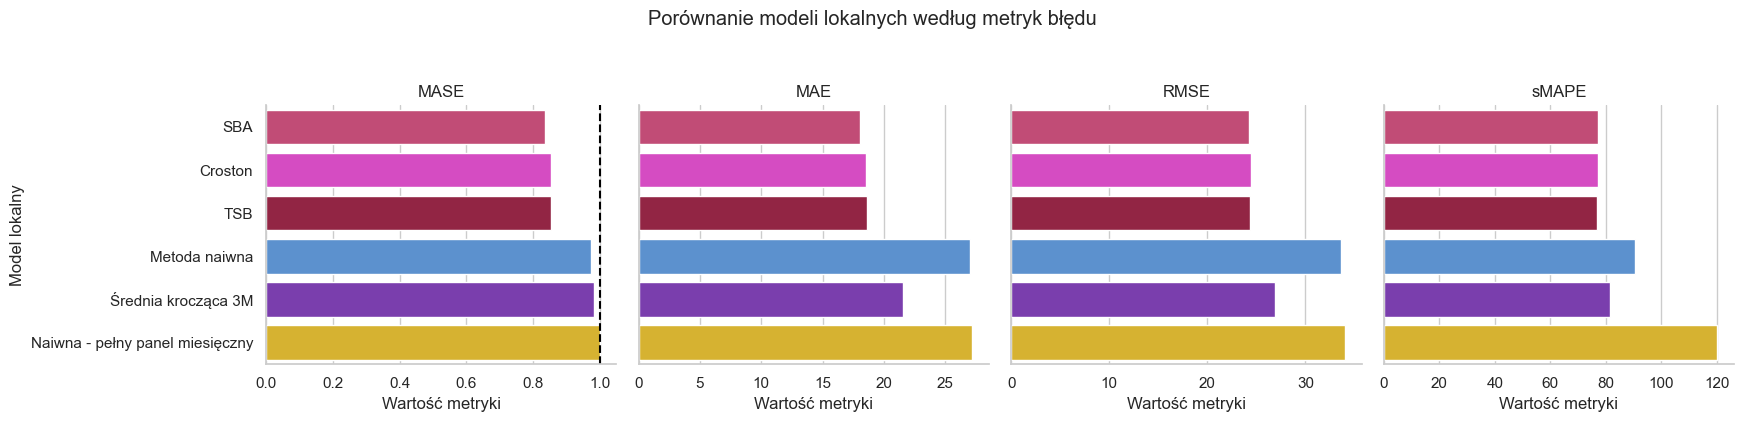

In [687]:
all_forecasts_local = (
    pd.concat([
        naive_forecast,
        naive_zero_forecast,
        moving_average_forecast,
        croston_forecast,
        sba_forecast,
        tsb_forecast
    ], ignore_index=True)
    .dropna(subset=["y_true", "y_pred"])
)

display(all_forecasts_local.head())

print(
    "Liczba prognoz:", len(all_forecasts_local),
    "| Liczba modeli:", all_forecasts_local["model"].nunique()
)
display(all_forecasts_local["model"].value_counts())

forecast_check_local = (
    all_forecasts_local.groupby("model", observed=True)
    .agg(
        liczba_prognoz=("y_pred", "size"),
        liczba_produktow=("produkt_id", "nunique"),
        liczba_grup=("grupa", "nunique")
    )
    .reset_index()
)

display(forecast_check_local)

metrics_product_local, results_local = evaluate_forecasts(
    all_forecasts_local, benchmark_mae_by_product
)

results_local = (
    results_local
    .sort_values("mase")
    .reset_index(drop=True)
    .assign(model_nazwa=lambda x: x["model"].map(model_labels))
)

display(results_local.round(3))

metrics_to_plot = ["mase", "mae", "rmse", "smape"]
metric_labels = {
    "mase": "MASE", "mae": "MAE",
    "rmse": "RMSE", "smape": "sMAPE"
}

model_order = results_local["model_nazwa"].tolist()

metrics_local_long = (
    results_local
    .melt(
        id_vars=["model", "model_nazwa"],
        value_vars=metrics_to_plot,
        var_name="metryka",
        value_name="wartosc"
    )
    .replace({"metryka": metric_labels})
)

g = sns.catplot(
    data=metrics_local_long,
    x="wartosc", y="model_nazwa",
    col="metryka", kind="bar",
    hue="model_nazwa",
    order=model_order,
    palette=model_palette,
    sharex=False,
    height=4, aspect=1.1,
    legend=False
)

g.set_axis_labels("Wartość metryki", "Model lokalny")
g.set_titles("{col_name}")
g.fig.suptitle("Porównanie modeli lokalnych według metryk błędu", y=1.05)

# Benchmark dotyczy MASE
g.axes.flat[0].axvline(1, color="black", linestyle="--", linewidth=1.5)

plt.tight_layout()
plt.show()

Najlepsze wyniki spośród modeli lokalnych uzyskały metody SBA, Crostona i TSB, a różnice między nimi były niewielkie. SBA osiągnął najniższą średnią MASE oraz najniższe MAE i RMSE, natomiast TSB uzyskał najlepszy wynik sMAPE. Słabsze rezultaty odnotowano dla metody naiwnej i średniej kroczącej, a najsłabiej wypadł benchmark oparty na pełnym panelu miesięcznym.

# Modele globalne

W przypadku modeli globalnych zastosowano podejście dwuetapowe dla prognozowania sprzedaży nieregularnej. W pierwszym etapie klasyfikator LightGBM przewidywał, czy w danym miesiącu wystąpi sprzedaż produktu (0 - nie występuje sprzedaż, 1 - sprzedaż występuje). W drugim etapie, dla miesięcy zaklasyfikowanych jako sprzedażowe, prognozowano wielkość sprzedaży za pomocą jednego z trzech regresorów: Ridge, Random Forest lub LightGBM Regressor.

## Przygotowanie panelu klasyfikacyjnego 0/1

In [688]:
product_info = (
    df_model.groupby("produkt_id", observed=True)
    [["symbol_produktu", "nazwa_produktu", "grupa", "jednostka"]]
    .first()
    .reset_index()
)

df_classification = pd.concat([
    pd.DataFrame({
        "produkt_id": pid,
        "miesiac": pd.date_range(g["miesiac"].min(), g["miesiac"].max(), freq="MS")
    })
    for pid, g in df_model.groupby("produkt_id", observed=True)
], ignore_index=True)

df_classification = (
    df_classification
    .merge(product_info, on="produkt_id", how="left")
    .merge(
        df_model[["produkt_id", "miesiac", "sprzedaz_ilosc"]],
        on=["produkt_id", "miesiac"],
        how="left"
    )
)

df_classification["czy_sprzedaz"] = df_classification["sprzedaz_ilosc"].notna().astype(int)

display(df_classification.head())

print(
    "Shape:", df_classification.shape,
    "| Produkty:", df_classification["produkt_id"].nunique()
)

display(pd.DataFrame({
    "liczba": df_classification["czy_sprzedaz"].value_counts(),
    "procent": df_classification["czy_sprzedaz"].value_counts(normalize=True).mul(100).round(2)
}))

,produkt_id,miesiac,symbol_produktu,nazwa_produktu,grupa,jednostka,sprzedaz_ilosc,czy_sprzedaz
0,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,2020-01-01,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,43.00,1
1,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,2020-02-01,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,10.00,1
2,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,2020-03-01,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,372.27,1
3,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,2020-04-01,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,25.00,1
4,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,2020-05-01,06 B-1 (3/8''x7/32'') RD,Spinka łańcucha jednorzędowego,lancuchy_standardowe,szt,57.00,1


Shape: (7403, 8) | Produkty: 105


,liczba,procent
czy_sprzedaz,,
1,5673,76.63
0,1730,23.37


# Przygotowanie cech do klasyfikatora

In [689]:
# Usunięcie wcześniej utworzonych cech
df_classification = df_classification.drop(columns=[
    "ostatni_miesiac_train", "zbior", "rok", "miesiac_roku", "kwartal",
    "nr_miesiaca_panel", "lag_czy_sprzedaz_1", "lag_czy_sprzedaz_2",
    "lag_czy_sprzedaz_3", "rolling_czy_sprzedaz_3", "rolling_czy_sprzedaz_6",
    "miesiac_sprzedazy", "poprzedni_miesiac_sprzedazy",
    "miesiace_od_poprzedniej_sprzedazy"
], errors="ignore")

# Podział train/test i cechy kalendarzowe
train_cutoff = (
    train.groupby("produkt_id", observed=True)["miesiac"]
    .max()
    .rename("ostatni_miesiac_train")
)

df_classification = (
    df_classification
    .merge(train_cutoff, on="produkt_id", how="left")
    .sort_values(["produkt_id", "miesiac"])
    .reset_index(drop=True)
)

df_classification["zbior"] = np.where(
    df_classification["miesiac"] <= df_classification["ostatni_miesiac_train"],
    "train", "test"
)

df_classification["rok"] = df_classification["miesiac"].dt.year
df_classification["miesiac_roku"] = df_classification["miesiac"].dt.month
df_classification["kwartal"] = df_classification["miesiac"].dt.quarter
df_classification["nr_miesiaca_panel"] = (
    df_classification.groupby("produkt_id", observed=True).cumcount() + 1
)

cols = [
    "lag_czy_sprzedaz_1", "lag_czy_sprzedaz_2", "lag_czy_sprzedaz_3",
    "rolling_czy_sprzedaz_3", "rolling_czy_sprzedaz_6",
    "miesiace_od_poprzedniej_sprzedazy"
]

df_classification[cols] = np.nan

train_mask = df_classification["zbior"].eq("train")
test_mask = df_classification["zbior"].eq("test")

# TRAIN
df_train_part = df_classification.loc[train_mask].copy()
g = df_train_part.groupby("produkt_id", observed=True)["czy_sprzedaz"]

for lag in [1, 2, 3]:
    df_train_part[f"lag_czy_sprzedaz_{lag}"] = g.shift(lag)

for okno in [3, 6]:
    df_train_part[f"rolling_czy_sprzedaz_{okno}"] = (
        g.transform(lambda x: x.shift(1).rolling(okno).mean())
    )

df_train_part["poprzedni_miesiac_sprzedazy"] = (
    df_train_part["miesiac"]
    .where(df_train_part["czy_sprzedaz"].eq(1))
    .groupby(df_train_part["produkt_id"], observed=True)
    .ffill()
    .groupby(df_train_part["produkt_id"], observed=True)
    .shift()
)

df_train_part["miesiace_od_poprzedniej_sprzedazy"] = (
    (df_train_part["miesiac"].dt.year - df_train_part["poprzedni_miesiac_sprzedazy"].dt.year) * 12
    + df_train_part["miesiac"].dt.month
    - df_train_part["poprzedni_miesiac_sprzedazy"].dt.month
)

df_classification.loc[df_train_part.index, cols] = df_train_part[cols]

# Historia z końca TRAIN
hist_train = (
    df_train_part.groupby("produkt_id", observed=True)
    .agg(
        lag_czy_sprzedaz_1=("czy_sprzedaz", "last"),
        lag_czy_sprzedaz_2=("czy_sprzedaz", lambda x: x.iloc[-2] if len(x) >= 2 else np.nan),
        lag_czy_sprzedaz_3=("czy_sprzedaz", lambda x: x.iloc[-3] if len(x) >= 3 else np.nan),
        rolling_czy_sprzedaz_3=("czy_sprzedaz", lambda x: x.tail(3).mean()),
        rolling_czy_sprzedaz_6=("czy_sprzedaz", lambda x: x.tail(6).mean()),
        poprzedni_miesiac_sprzedazy=("miesiac", lambda x: x[df_train_part.loc[x.index, "czy_sprzedaz"].eq(1)].max())
    )
)

# TEST
df_test_part = (
    df_classification.loc[test_mask, ["produkt_id", "miesiac"]]
    .merge(hist_train, on="produkt_id", how="left")
)

df_test_part["miesiace_od_poprzedniej_sprzedazy"] = (
    (df_test_part["miesiac"].dt.year - df_test_part["poprzedni_miesiac_sprzedazy"].dt.year) * 12
    + df_test_part["miesiac"].dt.month
    - df_test_part["poprzedni_miesiac_sprzedazy"].dt.month
)

df_classification.loc[test_mask, cols] = df_test_part[cols].values

In [690]:
print(
    "Shape:", df_classification.shape,
    "\n\nPodział train/test:"
)
display(df_classification["zbior"].value_counts())

print("Braki danych:")
display(df_classification.isna().sum())

print("Rozkład czy_sprzedaz w train/test:")
display(pd.crosstab(
    df_classification["zbior"],
    df_classification["czy_sprzedaz"],
    normalize="index"
).round(3))

Shape: (7403, 20) 

Podział train/test:


zbior
train    5798
test     1605
Name: count, dtype: int64

Braki danych:


produkt_id                              0
miesiac                                 0
symbol_produktu                         0
nazwa_produktu                          0
grupa                                   0
jednostka                               0
sprzedaz_ilosc                       1730
czy_sprzedaz                            0
ostatni_miesiac_train                   0
zbior                                   0
rok                                     0
miesiac_roku                            0
kwartal                                 0
nr_miesiaca_panel                       0
lag_czy_sprzedaz_1                    105
lag_czy_sprzedaz_2                    210
lag_czy_sprzedaz_3                    315
rolling_czy_sprzedaz_3                315
rolling_czy_sprzedaz_6                630
miesiace_od_poprzedniej_sprzedazy     105
dtype: int64

Rozkład czy_sprzedaz w train/test:


czy_sprzedaz,0,1
zbior,,
test,0.265,0.735
train,0.225,0.775


In [691]:
features_classification = [
    "produkt_id",
    "grupa",
    "jednostka",
    "rok",
    "miesiac_roku",
    "kwartal",
    "nr_miesiaca_panel",
    "lag_czy_sprzedaz_1",
    "lag_czy_sprzedaz_2",
    "lag_czy_sprzedaz_3",
    "rolling_czy_sprzedaz_3",
    "rolling_czy_sprzedaz_6",
    "miesiace_od_poprzedniej_sprzedazy"
]

In [692]:
df_clf_model = df_classification.copy()

df_clf_model["miesiace_od_poprzedniej_sprzedazy"] = (
    df_clf_model["miesiace_od_poprzedniej_sprzedazy"]
    .fillna(999)
)

lag_cols = [
    "lag_czy_sprzedaz_1",
    "lag_czy_sprzedaz_2",
    "lag_czy_sprzedaz_3",
    "rolling_czy_sprzedaz_3",
    "rolling_czy_sprzedaz_6"
]

df_clf_model[lag_cols] = df_clf_model[lag_cols].fillna(0)

In [693]:
clf_train = df_clf_model[df_clf_model["zbior"] == "train"].copy()
clf_test = df_clf_model[df_clf_model["zbior"] == "test"].copy()

X_clf_train = clf_train[features_classification]
y_clf_train = clf_train["czy_sprzedaz"]

X_clf_test = clf_test[features_classification]
y_clf_test = clf_test["czy_sprzedaz"]

print("X_clf_train:", X_clf_train.shape)
print("X_clf_test:", X_clf_test.shape)

print("\nRozkład y train:")
display(y_clf_train.value_counts(normalize=True).round(3))

print("\nRozkład y test:")
display(y_clf_test.value_counts(normalize=True).round(3))

X_clf_train: (5798, 13)
X_clf_test: (1605, 13)

Rozkład y train:


czy_sprzedaz
1    0.775
0    0.225
Name: proportion, dtype: float64


Rozkład y test:


czy_sprzedaz
1    0.735
0    0.265
Name: proportion, dtype: float64

In [694]:
cat_features_classification = [
    "produkt_id",
    "grupa",
    "jednostka"
]

for col in cat_features_classification:
    X_clf_train[col] = X_clf_train[col].astype("category")
    X_clf_test[col] = X_clf_test[col].astype("category")

# LGBMClassifier (0/1 - czy wystąpiła sprzedaż w danym miesiącu)

In [695]:
clf_model = LGBMClassifier(
    n_estimators=600,
    learning_rate=0.01,
    max_depth=-1,
    random_state=42,
    class_weight="balanced",
    verbose=-1
)

clf_model.fit(
    X_clf_train,
    y_clf_train,
    categorical_feature=cat_features_classification
)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.01
,n_estimators,600
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


,accuracy,precision,recall,f1,roc_auc
0,0.69595,0.747496,0.885593,0.810706,0.527409


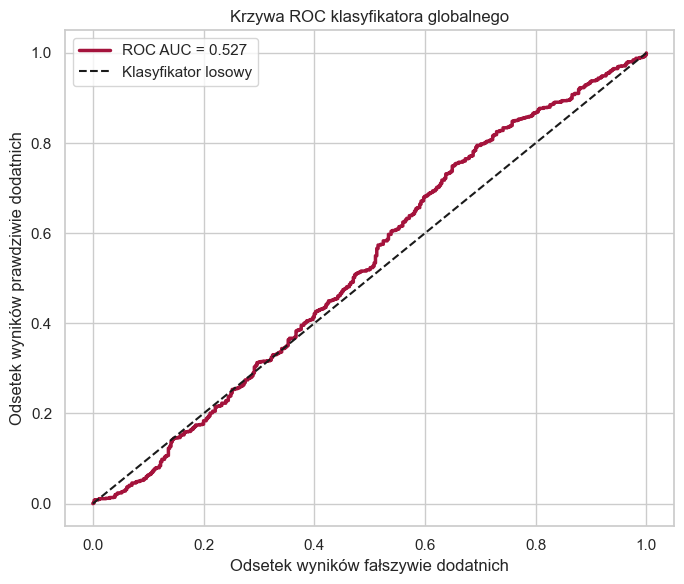

In [696]:
clf_prob = clf_model.predict_proba(X_clf_test)[:, 1]
clf_pred = (clf_prob >= 0.5).astype(int)

clf_test_results = clf_test[
    ["produkt_id", "grupa", "miesiac", "czy_sprzedaz"]
].copy()

clf_test_results["p_sprzedazy"] = clf_prob
clf_test_results["czy_sprzedaz_pred"] = clf_pred

classification_results = pd.DataFrame([{
    "accuracy": accuracy_score(y_clf_test, clf_pred),
    "precision": precision_score(y_clf_test, clf_pred, zero_division=0),
    "recall": recall_score(y_clf_test, clf_pred, zero_division=0),
    "f1": f1_score(y_clf_test, clf_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_clf_test, clf_prob)
}])

display(classification_results)

fpr, tpr, _ = roc_curve(y_clf_test, clf_prob)
auc = roc_auc_score(y_clf_test, clf_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color=colors[4], lw=2.5, label=f"ROC AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Klasyfikator losowy")
plt.title("Krzywa ROC klasyfikatora globalnego")
plt.xlabel("Odsetek wyników fałszywie dodatnich")
plt.ylabel("Odsetek wyników prawdziwie dodatnich")
plt.legend()
plt.tight_layout()
plt.show()

Klasyfikator charakteryzował się wysoką czułością równą 0.886, co oznacza, że poprawnie identyfikował znaczną część obserwacji, w których rzeczywiście wystąpiła sprzedaż. Precyzja wyniosła 0.747, natomiast F1-score 0.811. Niższą wartość odnotowano dla dokładności klasyfikacji, która wyniosła 0.696. Szczególnie istotny jest jednak wynik ROC AUC. Krzywa przebiega w niewielkiej odległości od linii odpowiadającej klasyfikacji losowej, a wartość ROC AUC wyniosła 0.527. Wynik ten wskazuje na niewielką zdolność modelu do rozróżniania obserwacji ze sprzedażą i bez sprzedaży.

# Przygotowanie cech do modeli globalnych

In [697]:
reg_train = train.sort_values(["produkt_id", "miesiac"]).copy()
reg_test = test.sort_values(["produkt_id", "miesiac"]).copy()

# Cechy kalendarzowe - train
reg_train["rok"] = reg_train["miesiac"].dt.year
reg_train["miesiac_roku"] = reg_train["miesiac"].dt.month
reg_train["kwartal"] = reg_train["miesiac"].dt.quarter

# Lagi i średnie kroczące
reg_train["lag_1"] = reg_train.groupby("produkt_id", observed=True)["sprzedaz_ilosc"].shift(1)
reg_train["lag_2"] = reg_train.groupby("produkt_id", observed=True)["sprzedaz_ilosc"].shift(2)
reg_train["lag_3"] = reg_train.groupby("produkt_id", observed=True)["sprzedaz_ilosc"].shift(3)

reg_train["rolling_mean_3"] = (
    reg_train
    .groupby("produkt_id", observed=True)["sprzedaz_ilosc"]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

reg_train["rolling_mean_6"] = (
    reg_train
    .groupby("produkt_id", observed=True)["sprzedaz_ilosc"]
    .transform(lambda x: x.shift(1).rolling(6).mean())
)

reg_train["liczba_obserwacji_historycznych"] = (
    reg_train
    .groupby("produkt_id", observed=True)
    .cumcount()
)

reg_train = reg_train.dropna(subset=[
    "lag_1",
    "lag_2",
    "lag_3",
    "rolling_mean_3",
    "rolling_mean_6"
]).copy()

In [698]:
history_features_test = (
    train
    .sort_values(["produkt_id", "miesiac"])
    .groupby("produkt_id", observed=True)
    .agg(
        lag_1=("sprzedaz_ilosc", lambda x: x.iloc[-1]),
        lag_2=("sprzedaz_ilosc", lambda x: x.iloc[-2]),
        lag_3=("sprzedaz_ilosc", lambda x: x.iloc[-3]),
        rolling_mean_3=("sprzedaz_ilosc", lambda x: x.tail(3).mean()),
        rolling_mean_6=("sprzedaz_ilosc", lambda x: x.tail(6).mean()),
        liczba_obserwacji_historycznych=("sprzedaz_ilosc", "size")
    )
    .reset_index()
)

reg_test["rok"] = reg_test["miesiac"].dt.year
reg_test["miesiac_roku"] = reg_test["miesiac"].dt.month
reg_test["kwartal"] = reg_test["miesiac"].dt.quarter

reg_test = reg_test.merge(
    history_features_test,
    on="produkt_id",
    how="left"
)

In [699]:
numeric_features_regression = [
    "rok",
    "miesiac_roku",
    "kwartal",
    "lag_1",
    "lag_2",
    "lag_3",
    "rolling_mean_3",
    "rolling_mean_6",
    "liczba_obserwacji_historycznych"
]

categorical_features_regression = [
    "produkt_id",
    "grupa",
    "jednostka"
]

features_regression = (
    numeric_features_regression
    + categorical_features_regression
)

In [700]:
X_reg_train = reg_train[features_regression].copy()
y_reg_train = reg_train["sprzedaz_ilosc"].copy()

X_reg_test = reg_test[features_regression].copy()

reg_test_base = reg_test[[
    "produkt_id",
    "grupa",
    "miesiac",
    "sprzedaz_ilosc"
]].copy()

print("X_reg_train:", X_reg_train.shape)
print("X_reg_test:", X_reg_test.shape)
print("Braki w X_reg_train:", X_reg_train.isna().sum().sum())
print("Braki w X_reg_test:", X_reg_test.isna().sum().sum())

X_reg_train: (3863, 12)
X_reg_test: (1180, 12)
Braki w X_reg_train: 0
Braki w X_reg_test: 0


## LGBMClassifier × Ridge

In [701]:
ridge_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_regression),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_regression)
    ]
)

ridge_model = Pipeline(
    steps=[
        ("preprocessor", ridge_preprocessor),
        ("model", Ridge(alpha=1.0))
    ]
)

ridge_model.fit(X_reg_train, y_reg_train)

ridge_pred = ridge_model.predict(X_reg_test)
ridge_pred = np.clip(ridge_pred, 0, None)

prognoza końcowa = prawdopodobieństwo sprzedaży × prognozowana ilość

In [702]:
global_ridge_forecast = reg_test_base.copy()

global_ridge_forecast["y_pred_ilosc"] = ridge_pred

global_ridge_forecast = global_ridge_forecast.merge(
    clf_test_results[["produkt_id", "miesiac", "p_sprzedazy"]],
    on=["produkt_id", "miesiac"],
    how="left"
)

global_ridge_forecast["y_pred"] = (
    global_ridge_forecast["p_sprzedazy"]
    * global_ridge_forecast["y_pred_ilosc"]
)

global_ridge_forecast = global_ridge_forecast.rename(
    columns={"sprzedaz_ilosc": "y_true"}
)

global_ridge_forecast["model"] = "lgbm_classifier_ridge"

global_ridge_forecast = global_ridge_forecast[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred", "p_sprzedazy", "y_pred_ilosc"]
]

display(global_ridge_forecast.head())

print("Liczba prognoz:", len(global_ridge_forecast))
print("Liczba produktów:", global_ridge_forecast["produkt_id"].nunique())
print("Braki w y_pred:", global_ridge_forecast["y_pred"].isna().sum())
print("Braki w p_sprzedazy:", global_ridge_forecast["p_sprzedazy"].isna().sum())

,model,produkt_id,grupa,miesiac,y_true,y_pred,p_sprzedazy,y_pred_ilosc
0,lgbm_classifier_ridge,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,90.918492,0.868940,104.631532
1,lgbm_classifier_ridge,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,92.763134,0.898032,103.295973
2,lgbm_classifier_ridge,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,92.073865,0.892284,103.189009
3,lgbm_classifier_ridge,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,39.212369,0.380400,103.082045
4,lgbm_classifier_ridge,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,95.295329,0.853032,111.713719


Liczba prognoz: 1180
Liczba produktów: 105
Braki w y_pred: 0
Braki w p_sprzedazy: 0


## LGBMClassifier × Random Forest

In [703]:
rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features_regression),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_regression)
    ]
)

rf_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_reg_train, y_reg_train)

rf_pred = rf_model.predict(X_reg_test)
rf_pred = np.clip(rf_pred, 0, None)

In [704]:
global_rf_forecast = reg_test_base.copy()

global_rf_forecast["y_pred_ilosc"] = rf_pred

global_rf_forecast = global_rf_forecast.merge(
    clf_test_results[["produkt_id", "miesiac", "p_sprzedazy"]],
    on=["produkt_id", "miesiac"],
    how="left"
)

global_rf_forecast["y_pred"] = (
    global_rf_forecast["p_sprzedazy"]
    * global_rf_forecast["y_pred_ilosc"]
)

global_rf_forecast = global_rf_forecast.rename(
    columns={"sprzedaz_ilosc": "y_true"}
)

global_rf_forecast["model"] = "lgbm_classifier_random_forest"

global_rf_forecast = global_rf_forecast[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred", "p_sprzedazy", "y_pred_ilosc"]
]

display(global_rf_forecast.head())

print("Liczba prognoz:", len(global_rf_forecast))
print("Liczba produktów:", global_rf_forecast["produkt_id"].nunique())
print("Braki w y_pred:", global_rf_forecast["y_pred"].isna().sum())
print("Braki w p_sprzedazy:", global_rf_forecast["p_sprzedazy"].isna().sum())

,model,produkt_id,grupa,miesiac,y_true,y_pred,p_sprzedazy,y_pred_ilosc
0,lgbm_classifier_random_forest,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,156.426104,0.868940,180.019516
1,lgbm_classifier_random_forest,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,160.889845,0.898032,179.158168
2,lgbm_classifier_random_forest,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,158.721448,0.892284,177.882279
3,lgbm_classifier_random_forest,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,67.523992,0.380400,177.508052
4,lgbm_classifier_random_forest,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,161.090718,0.853032,188.844967


Liczba prognoz: 1180
Liczba produktów: 105
Braki w y_pred: 0
Braki w p_sprzedazy: 0


## LGBMClassifier × LGBMRegressor

In [705]:
X_reg_train_lgbm = X_reg_train.copy()
X_reg_test_lgbm = X_reg_test.copy()

for col in categorical_features_regression:
    X_reg_train_lgbm[col] = X_reg_train_lgbm[col].astype("category")
    X_reg_test_lgbm[col] = X_reg_test_lgbm[col].astype("category")

lgbm_reg_model = LGBMRegressor(
    n_estimators=600,
    learning_rate=0.01,
    max_depth=-1,
    random_state=42,
    verbose=-1
)

lgbm_reg_model.fit(
    X_reg_train_lgbm,
    y_reg_train,
    categorical_feature=categorical_features_regression
)

lgbm_reg_pred = lgbm_reg_model.predict(X_reg_test_lgbm)
lgbm_reg_pred = np.clip(lgbm_reg_pred, 0, None)

In [706]:
global_lgbm_forecast = reg_test_base.copy()

global_lgbm_forecast["y_pred_ilosc"] = lgbm_reg_pred

global_lgbm_forecast = global_lgbm_forecast.merge(
    clf_test_results[["produkt_id", "miesiac", "p_sprzedazy"]],
    on=["produkt_id", "miesiac"],
    how="left"
)

global_lgbm_forecast["y_pred"] = (
    global_lgbm_forecast["p_sprzedazy"]
    * global_lgbm_forecast["y_pred_ilosc"]
)

global_lgbm_forecast = global_lgbm_forecast.rename(
    columns={"sprzedaz_ilosc": "y_true"}
)

global_lgbm_forecast["model"] = "lgbm_classifier_lgbm_regressor"

global_lgbm_forecast = global_lgbm_forecast[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred", "p_sprzedazy", "y_pred_ilosc"]
]

display(global_lgbm_forecast.head())

print("Liczba prognoz:", len(global_lgbm_forecast))
print("Liczba produktów:", global_lgbm_forecast["produkt_id"].nunique())
print("Braki w y_pred:", global_lgbm_forecast["y_pred"].isna().sum())
print("Braki w p_sprzedazy:", global_lgbm_forecast["p_sprzedazy"].isna().sum())

,model,produkt_id,grupa,miesiac,y_true,y_pred,p_sprzedazy,y_pred_ilosc
0,lgbm_classifier_lgbm_regressor,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,165.504338,0.868940,190.467000
1,lgbm_classifier_lgbm_regressor,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,170.499635,0.898032,189.859107
2,lgbm_classifier_lgbm_regressor,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,169.408175,0.892284,189.859107
3,lgbm_classifier_lgbm_regressor,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,50.534899,0.380400,132.846876
4,lgbm_classifier_lgbm_regressor,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,199.119035,0.853032,233.425167


Liczba prognoz: 1180
Liczba produktów: 105
Braki w y_pred: 0
Braki w p_sprzedazy: 0


# LGBMClassifier x metoda naiwna

In [707]:
naive_regressor_values = (
    train
    .sort_values(["produkt_id", "miesiac"])
    .groupby("produkt_id", observed=True)
    .tail(1)
    [["produkt_id", "sprzedaz_ilosc"]]
    .rename(columns={"sprzedaz_ilosc": "y_pred_ilosc"})
)

global_naive_forecast = (
    test[["produkt_id", "grupa", "miesiac", "sprzedaz_ilosc"]]
    .merge(naive_regressor_values, on="produkt_id", how="left")
    .merge(
        clf_test_results[
            ["produkt_id", "miesiac", "p_sprzedazy"]
        ],
        on=["produkt_id", "miesiac"],
        how="left"
    )
)

global_naive_forecast["y_pred"] = (
    global_naive_forecast["p_sprzedazy"]
    * global_naive_forecast["y_pred_ilosc"]
)

global_naive_forecast = global_naive_forecast.rename(
    columns={"sprzedaz_ilosc": "y_true"}
)

global_naive_forecast["model"] = "lgbm_classifier_naive"

global_naive_forecast = global_naive_forecast[
    [
        "model",
        "produkt_id",
        "grupa",
        "miesiac",
        "y_true",
        "y_pred",
        "p_sprzedazy",
        "y_pred_ilosc"
    ]
]

display(global_naive_forecast.head())

print("Liczba prognoz:", len(global_naive_forecast))
print("Liczba produktów:", global_naive_forecast["produkt_id"].nunique())
print("Braki w y_pred:", global_naive_forecast["y_pred"].isna().sum())
print("Braki w p_sprzedazy:", global_naive_forecast["p_sprzedazy"].isna().sum())

,model,produkt_id,grupa,miesiac,y_true,y_pred,p_sprzedazy,y_pred_ilosc
0,lgbm_classifier_naive,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-09-01,13.00,1.737879,0.868940,2.0
1,lgbm_classifier_naive,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-10-01,336.27,1.796065,0.898032,2.0
2,lgbm_classifier_naive,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-11-01,20.00,1.784567,0.892284,2.0
3,lgbm_classifier_naive,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2024-12-01,70.00,0.760799,0.380400,2.0
4,lgbm_classifier_naive,06 B-1 (3/8''x7/32'') RD | Spinka łańcucha jed...,lancuchy_standardowe,2025-01-01,22.00,1.706063,0.853032,2.0


Liczba prognoz: 1180
Liczba produktów: 105
Braki w y_pred: 0
Braki w p_sprzedazy: 0


# Podsumowanie i ocena modeli globalnych

Liczba prognoz: 4720 | Liczba modeli: 4


model
lgbm_classifier_ridge             1180
lgbm_classifier_random_forest     1180
lgbm_classifier_lgbm_regressor    1180
lgbm_classifier_naive             1180
Name: count, dtype: int64

,model,mae,rmse,smape,mase,mase_mediana,model_nazwa
0,lgbm_classifier_naive,24.316,31.310,92.421,0.932,0.940,Klasyfikator LGBM + metoda naiwna
1,lgbm_classifier_lgbm_regressor,19.902,25.690,79.435,0.962,0.865,Klasyfikator LGBM + regresor LGBM
2,lgbm_classifier_ridge,18.701,24.372,84.657,0.989,0.898,Klasyfikator LGBM + regresja Ridge
3,lgbm_classifier_random_forest,22.224,27.210,83.234,1.071,0.920,Klasyfikator LGBM + las losowy


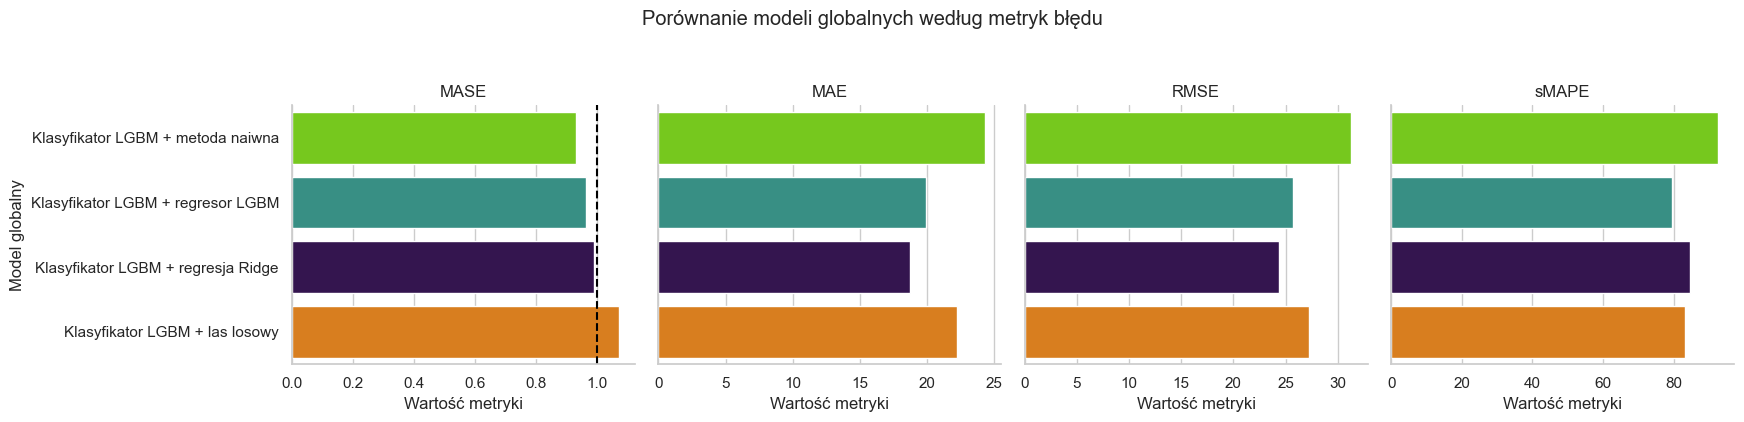

In [708]:
all_forecasts_global = (
    pd.concat([
        global_ridge_forecast,
        global_rf_forecast,
        global_lgbm_forecast,
        global_naive_forecast
    ], ignore_index=True)
    [["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred"]]
    .dropna(subset=["y_true", "y_pred"])
)

print(
    "Liczba prognoz:", len(all_forecasts_global),
    "| Liczba modeli:", all_forecasts_global["model"].nunique()
)
display(all_forecasts_global["model"].value_counts())

metrics_product_global, results_global = evaluate_forecasts(
    all_forecasts_global, benchmark_mae_by_product
)

results_global = (
    results_global
    .sort_values("mase")
    .reset_index(drop=True)
    .assign(model_nazwa=lambda x: x["model"].map(model_labels))
)

display(results_global.round(3))

metrics_to_plot = ["mase", "mae", "rmse", "smape"]
metric_labels = {
    "mase": "MASE", "mae": "MAE",
    "rmse": "RMSE", "smape": "sMAPE"
}

model_order = results_global["model_nazwa"].tolist()

metrics_global_long = (
    results_global
    .melt(
        id_vars=["model", "model_nazwa"],
        value_vars=metrics_to_plot,
        var_name="metryka",
        value_name="wartosc"
    )
    .replace({"metryka": metric_labels})
)

g = sns.catplot(
    data=metrics_global_long,
    x="wartosc", y="model_nazwa",
    col="metryka", kind="bar",
    hue="model_nazwa",
    order=model_order,
    palette=model_palette,
    sharex=False,
    height=4, aspect=1.1,
    legend=False
)

g.set_axis_labels("Wartość metryki", "Model globalny")
g.set_titles("{col_name}")
g.fig.suptitle("Porównanie modeli globalnych według metryk błędu", y=1.05)

# Benchmark MASE = 1
g.axes.flat[0].axvline(1, color="black", linestyle="--", linewidth=1.5)

plt.tight_layout()
plt.show()

Najlepszy wynik pod względem średniej MASE uzyskał model łączący klasyfikator LightGBM z metodą naiwną. Najniższe wartości MAE i RMSE osiągnął model z regresją Ridge, natomiast najlepszy wynik sMAPE uzyskał model z regresorem LightGBM. Najsłabiej pod względem MASE wypadł model wykorzystujący regresor lasu losowego.

# Porównanie wszystkich modeli

In [709]:
def wybierz_produkty_przykladowe(df, n=4):
    stats = (
        df.drop_duplicates(["produkt_id", "miesiac"])
        .groupby("produkt_id", observed=True)
        .agg(
            suma_sprzedazy=("y_true", "sum"),
            liczba_miesiecy=("miesiac", "nunique"),
            udzial_zer=("y_true", lambda x: (x == 0).mean()),
            srednia=("y_true", "mean"),
            odchylenie=("y_true", "std")
        )
        .reset_index()
    )

    stats["cv"] = stats["odchylenie"] / (stats["srednia"] + 1e-8)

    produkty = []

    produkty.append(stats.sort_values("liczba_miesiecy", ascending=False).iloc[0]["produkt_id"])
    produkty.append(stats.sort_values("udzial_zer", ascending=False).iloc[0]["produkt_id"])
    produkty.append(stats.sort_values("suma_sprzedazy", ascending=False).iloc[0]["produkt_id"])
    produkty.append(stats.sort_values("cv", ascending=False).iloc[0]["produkt_id"])

    produkty = list(dict.fromkeys(produkty))

    return produkty[:n]

In [710]:
all_forecasts_total = pd.concat(
    [
        all_forecasts_local,
        all_forecasts_global
    ],
    ignore_index=True
)

all_forecasts_total = all_forecasts_total[
    ["model", "produkt_id", "grupa", "miesiac", "y_true", "y_pred"]
].copy()

all_forecasts_total = all_forecasts_total.dropna(
    subset=["y_true", "y_pred"]
).copy()

print("Liczba wszystkich modeli:", all_forecasts_total["model"].nunique())

display(all_forecasts_total["model"].value_counts())

Liczba wszystkich modeli: 10


model
naiwna                            1180
naiwna_panel_zero                 1180
srednia_kroczaca_3                1180
croston                           1180
sba                               1180
tsb                               1180
lgbm_classifier_ridge             1180
lgbm_classifier_random_forest     1180
lgbm_classifier_lgbm_regressor    1180
lgbm_classifier_naive             1180
Name: count, dtype: int64

In [711]:
metrics_product_total, results_total = evaluate_forecasts(
    all_forecasts_total,
    benchmark_mae_by_product
)

results_total = results_total.sort_values("mase").reset_index(drop=True)

results_display = results_total.round({
    "mae": 3,
    "rmse": 3,
    "smape": 2,
    "mase": 3,
    "mase_mediana": 3
})

display(
    results_display.style.highlight_min(
        subset=["mae", "rmse", "smape", "mase", "mase_mediana"],
        color="deeppink"
    )
)

,model,mae,rmse,smape,mase,mase_mediana
0,sba,18.091000,24.245000,77.050000,0.835000,0.829000
1,croston,18.560000,24.430000,77.090000,0.854000,0.826000
2,tsb,18.603000,24.383000,76.940000,0.855000,0.831000
3,lgbm_classifier_naive,24.316000,31.310000,92.420000,0.932000,0.940000
4,lgbm_classifier_lgbm_regressor,19.902000,25.690000,79.430000,0.962000,0.865000
5,naiwna,27.033000,33.627000,90.470000,0.975000,1.000000
6,srednia_kroczaca_3,21.531000,26.878000,81.610000,0.982000,0.905000
7,lgbm_classifier_ridge,18.701000,24.372000,84.660000,0.989000,0.898000
8,naiwna_panel_zero,27.221000,34.020000,120.200000,1.000000,1.000000
9,lgbm_classifier_random_forest,22.224000,27.210000,83.230000,1.071000,0.920000


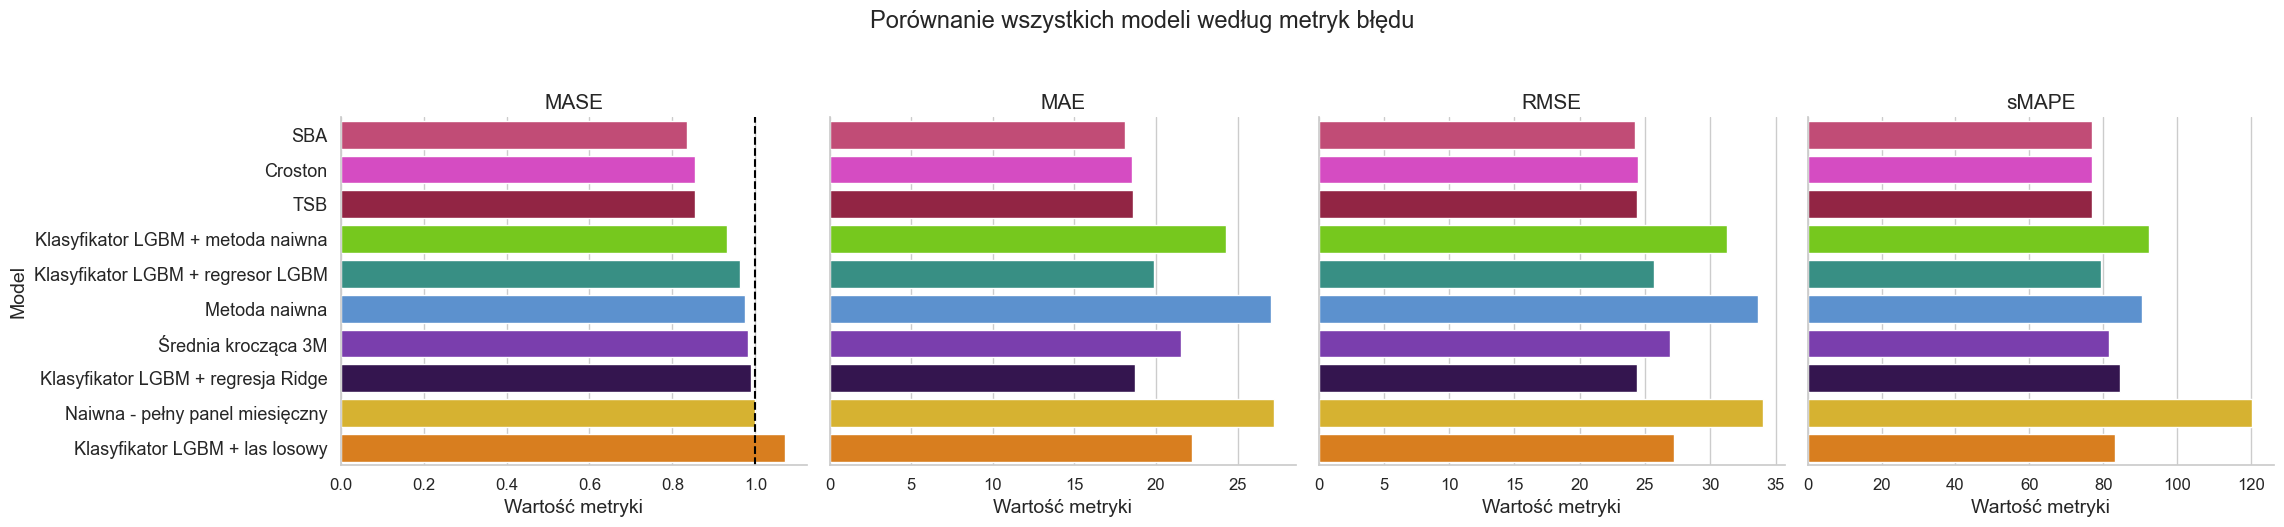

In [712]:
metrics_to_plot = ["mase", "mae", "rmse", "smape"]

metric_labels = {
    "mase": "MASE",
    "mae": "MAE",
    "rmse": "RMSE",
    "smape": "sMAPE"
}

results_total_plot = results_total.copy()


results_total_plot["model_nazwa"] = results_total_plot["model"].map(model_labels)

model_order = (
    results_total_plot
    .sort_values("mase")["model_nazwa"]
    .tolist()
)

metrics_total_long = results_total_plot.melt(
    id_vars=["model", "model_nazwa"],
    value_vars=metrics_to_plot,
    var_name="metryka",
    value_name="wartosc"
)

metrics_total_long["metryka"] = metrics_total_long["metryka"].replace(metric_labels)

g = sns.catplot(
    data=metrics_total_long,
    x="wartosc",
    y="model_nazwa",
    col="metryka",
    kind="bar",
    hue="model_nazwa",
    order=model_order,
    palette=model_palette,
    sharex=False,
    height=5,
    aspect=1.15,
    legend=False
)

g.set_axis_labels(
    "Wartość metryki",
    "Model",
    fontsize=14
)

g.set_titles(
    "{col_name}",
    size=15
)

for ax in g.axes.flat:
    ax.tick_params(axis="x", labelsize=12)
    ax.tick_params(axis="y", labelsize=13)
    ax.xaxis.label.set_size(14)
    ax.yaxis.label.set_size(14)

g.axes.flat[0].axvline(1, color="black", linestyle="--", linewidth=1.5)


plt.suptitle(
    "Porównanie wszystkich modeli według metryk błędu",
    y=1.05,
    fontsize=17
)

plt.tight_layout()
plt.show()

Najlepiej ogólnie wypadają SBA, Croston i TSB, szczególnie pod względem MASE, MAE i RMSE. Wśród modeli globalnych najlepsze wyniki osiągają warianty z regresją Ridge i regresorem LightGBM. Najsłabiej wypadają benchmark naiwny, globalny model z lasem losowym oraz warianty oparte na metodzie naiwnej, szczególnie dla sMAPE.

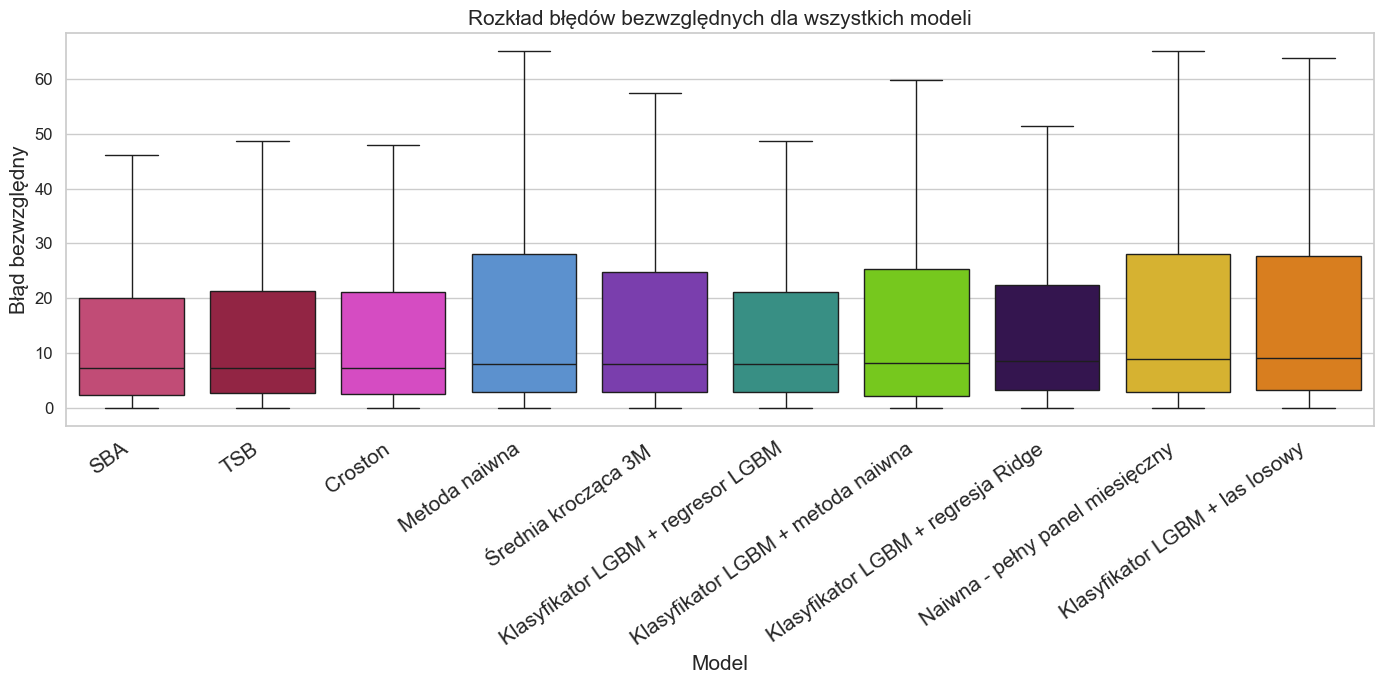

In [713]:
plot_data = all_forecasts_total.copy()

plot_data["model_nazwa"] = plot_data["model"].map(model_labels)
plot_data["blad_bezwzgledny"] = (plot_data["y_true"] - plot_data["y_pred"]).abs()

order = (
    plot_data
    .groupby("model_nazwa", observed=True)["blad_bezwzgledny"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=plot_data,
    x="model_nazwa",
    y="blad_bezwzgledny",
    hue="model_nazwa",
    order=order,
    palette=model_palette,
    showfliers=False,
    legend=False
)

plt.title("Rozkład błędów bezwzględnych dla wszystkich modeli", fontsize=15)
plt.xlabel("Model", fontsize=15)
plt.ylabel("Błąd bezwzględny", fontsize=15)
plt.xticks(rotation=35, ha="right", fontsize=15)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

Na wykresie powyżej przedstawiono rozkład bezwzględnych błędów prognoz uzyskanych dla poszczególnych modeli. Linia wewnątrz każdego pudełka oznacza medianę błędu bezwzględnego, natomiast jego dolna i górna granica odpowiadają pierwszemu i trzeciemu kwartylowi. Mediany dla wszystkich modeli kształtują się na stosunkowo zbliżonym poziomie.
Największą rozpiętość pudełek można zaobserwować przede wszystkim dla wariantów wykorzystujących metodę naiwną oraz globalnego modelu z regresorem lasu losowego. Modele te charakteryzują się również wysokimi wartościami górnych wąsów, co wskazuje na większe zróżnicowanie błędów. Relatywnie mniejsze zróżnicowanie widoczne jest dla SBA, TSB i metody Crostona, a wśród modeli globalnych dla modeli z regresorem LightGBM oraz regresją Ridge.

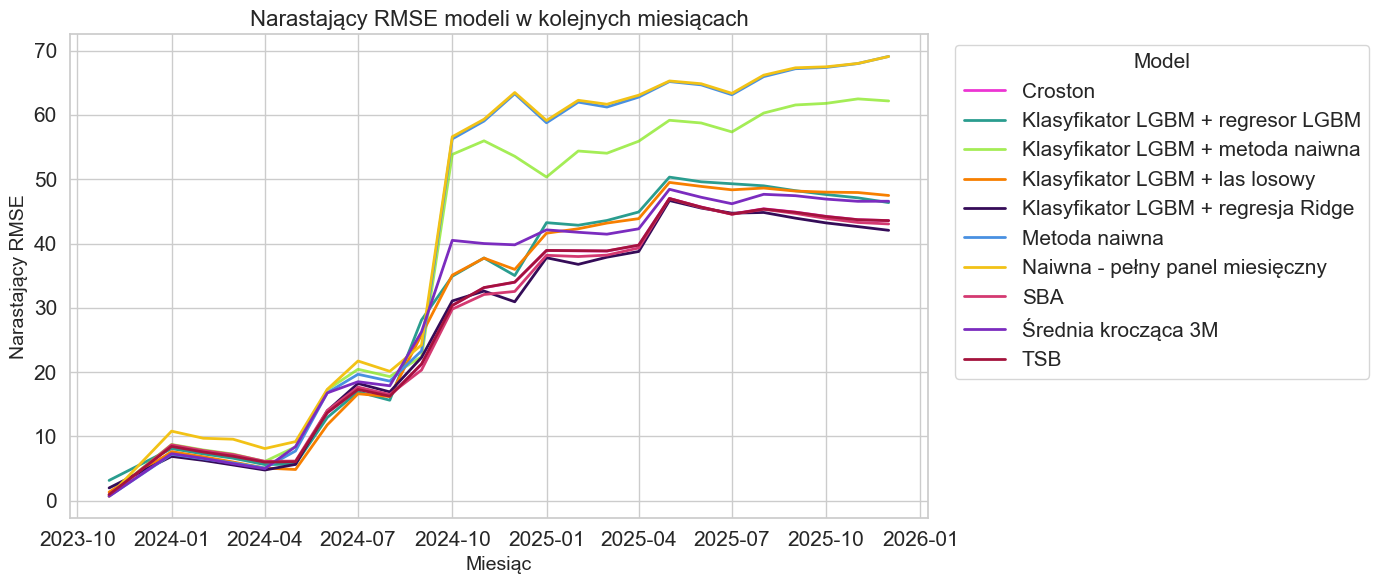

In [714]:
plot_data = all_forecasts_total.copy()


plot_data["model_nazwa"] = plot_data["model"].map(model_labels)
plot_data["blad_kwadratowy"] = (plot_data["y_true"] - plot_data["y_pred"]) ** 2

monthly_errors = (
    plot_data
    .groupby(["miesiac", "model", "model_nazwa"], observed=True)
    .agg(
        suma_bledu_kwadratowego=("blad_kwadratowy", "sum"),
        liczba_obserwacji=("blad_kwadratowy", "count")
    )
    .reset_index()
    .sort_values(["model", "miesiac"])
)

monthly_errors["skumulowany_blad_kwadratowy"] = (
    monthly_errors
    .groupby("model", observed=True)["suma_bledu_kwadratowego"]
    .cumsum()
)

monthly_errors["skumulowana_liczba"] = (
    monthly_errors
    .groupby("model", observed=True)["liczba_obserwacji"]
    .cumsum()
)

monthly_errors["skumulowany_rmse"] = np.sqrt(
    monthly_errors["skumulowany_blad_kwadratowy"] / monthly_errors["skumulowana_liczba"]
)

plt.figure(figsize=(14, 6)) 

for model in monthly_errors["model"].unique(): 
    temp = monthly_errors[monthly_errors["model"] == model] 
     
    plt.plot( 
        temp["miesiac"], 
        temp["skumulowany_rmse"], 
        linewidth=2, 
        color=model_colors[model], 
        label=model_labels[model] 
    ) 

plt.title("Narastający RMSE modeli w kolejnych miesiącach", fontsize=16)
plt.xlabel("Miesiąc", fontsize=14)
plt.ylabel("Narastający RMSE", fontsize=14)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=15,
    title_fontsize=15
)

plt.tight_layout()
plt.show()

Na wykresie przedstawiono wartości RMSE liczone narastająco dla wszystkich analizowanych modeli w kolejnych miesiącach okresu testowego. Do około sierpnia 2024 r. przebieg błędu był stosunkowo podobny dla większości modeli, natomiast w kolejnych miesiącach widoczne stało się wyraźniejsze zróżnicowanie. Największy wzrost wystąpił dla metody naiwnej, benchmarku opartego na pełnym panelu miesięcznym oraz modelu łączącego klasyfikator LightGBM z metodą naiwną, co jest zgodne z ich relatywnie wysokimi wartościami RMSE. Dla pozostałych modeli wartości błędu utrzymywały się na bardziej zbliżonym i niższym poziomie. Okresowe spadki oznaczają natomiast, że prognozy dodawane w kolejnych miesiącach charakteryzowały się przeciętnie niższymi błędami niż obserwacje uwzględnione wcześniej.

# Porównanie wszystkich modeli na tle produktów 

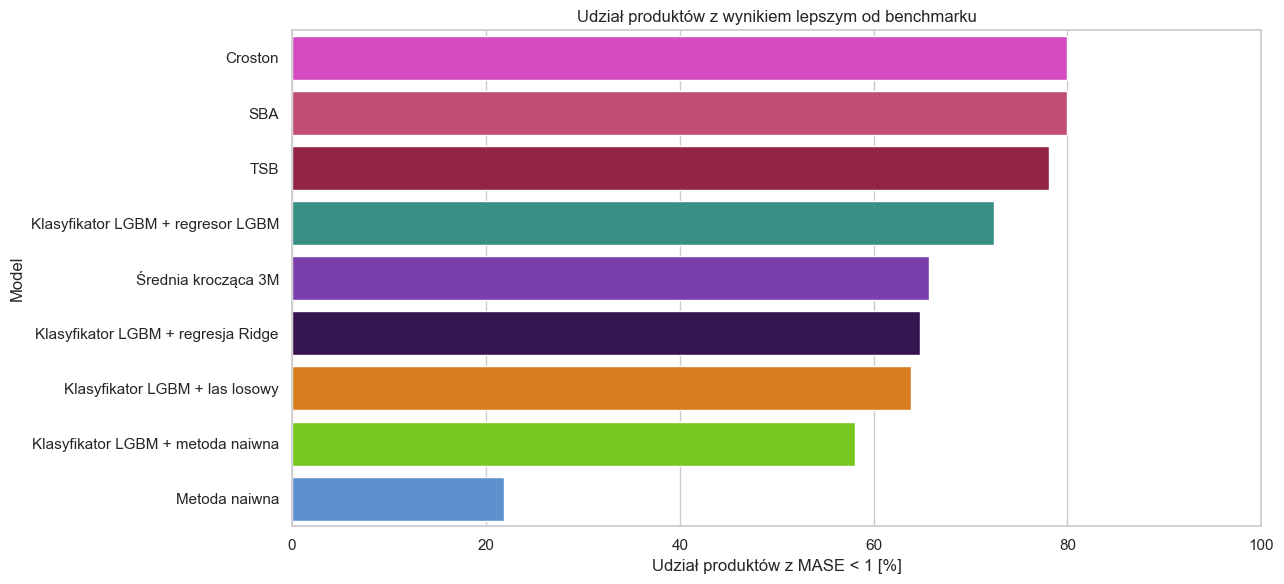

In [715]:
better_than_benchmark = (
    metrics_product_total
    .assign(lepszy_od_benchmarku=lambda x: x["mase"] < 1)
    .groupby("model", observed=True)
    .agg(
        liczba_produktow=("produkt_id", "nunique"),
        liczba_lepszych=("lepszy_od_benchmarku", "sum"),
        udzial_lepszych=("lepszy_od_benchmarku", "mean")
    )
    .reset_index()
)

better_than_benchmark = better_than_benchmark[
    better_than_benchmark["model"] != "naiwna_panel_zero"
].copy()

better_than_benchmark["model_nazwa"] = (
    better_than_benchmark["model"].map(model_labels)
)

better_than_benchmark["udzial_lepszych_proc"] = (
    better_than_benchmark["udzial_lepszych"] * 100
)

better_than_benchmark = better_than_benchmark.sort_values(
    "udzial_lepszych_proc",
    ascending=False
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=better_than_benchmark,
    x="udzial_lepszych_proc",
    y="model_nazwa",
    hue="model_nazwa",
    palette=model_palette,
    legend=False
)

plt.title("Udział produktów z wynikiem lepszym od benchmarku")
plt.xlabel("Udział produktów z MASE < 1 [%]")
plt.ylabel("Model")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

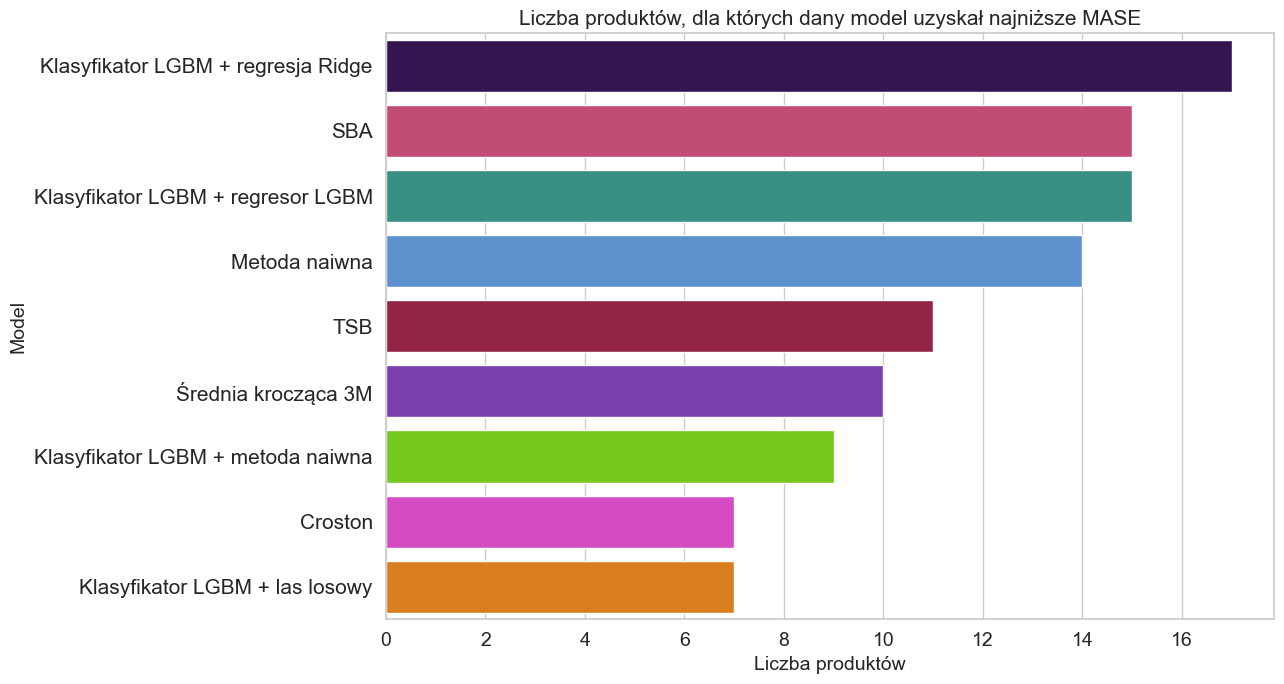

In [716]:
winner_product = (
    metrics_product_total
    .dropna(subset=["mase"])
    .query("model != 'naiwna_panel_zero'")
    .sort_values(["produkt_id", "mase"])
    .groupby("produkt_id", observed=True)
    .first()
    .reset_index()
)

winner_product["model_nazwa"] = winner_product["model"].map(model_labels)

winner_summary = (
    winner_product
    .groupby(["model", "model_nazwa"], observed=True)
    .agg(liczba_wygranych=("produkt_id", "nunique"))
    .reset_index()
)

winner_summary["udzial_proc"] = (
    winner_summary["liczba_wygranych"] / winner_summary["liczba_wygranych"].sum() * 100
)

winner_summary = winner_summary.sort_values("liczba_wygranych", ascending=False)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=winner_summary,
    x="liczba_wygranych",
    y="model_nazwa",
    hue="model_nazwa",
    palette=model_palette,
    legend=False
)

plt.title("Liczba produktów, dla których dany model uzyskał najniższe MASE", fontsize=15)
plt.xlabel("Liczba produktów", fontsize=14)
plt.ylabel("Model", fontsize=14)
plt.yticks(fontsize=15)
plt.xticks(fontsize=14)
plt.tight_layout()
plt.show()

Na powyższym wykresie przedstawiono liczbę produktów, dla których dany model uzyskał najniższą wartość MASE spośród wszystkich porównywanych metod. Najczęściej najlepszy wynik osiągał globalny model z regresją Ridge - dla 17 produktów. SBA oraz model z regresorem LightGBM były najlepsze dla 15 różnych produktów. Łącznie dla 57 ze 105 produktów najniższą wartość MASE uzyskał model lokalny, natomiast dla 48 produktów model globalny. Wyniki te wskazują, że mimo przewagi modeli lokalnych w ujęciu zagregowanym, modele globalne również często osiągały najlepsze wyniki na poziomie pojedynczych produktów, co potwierdza zróżnicowanie skuteczności metod pomiędzy produktami.

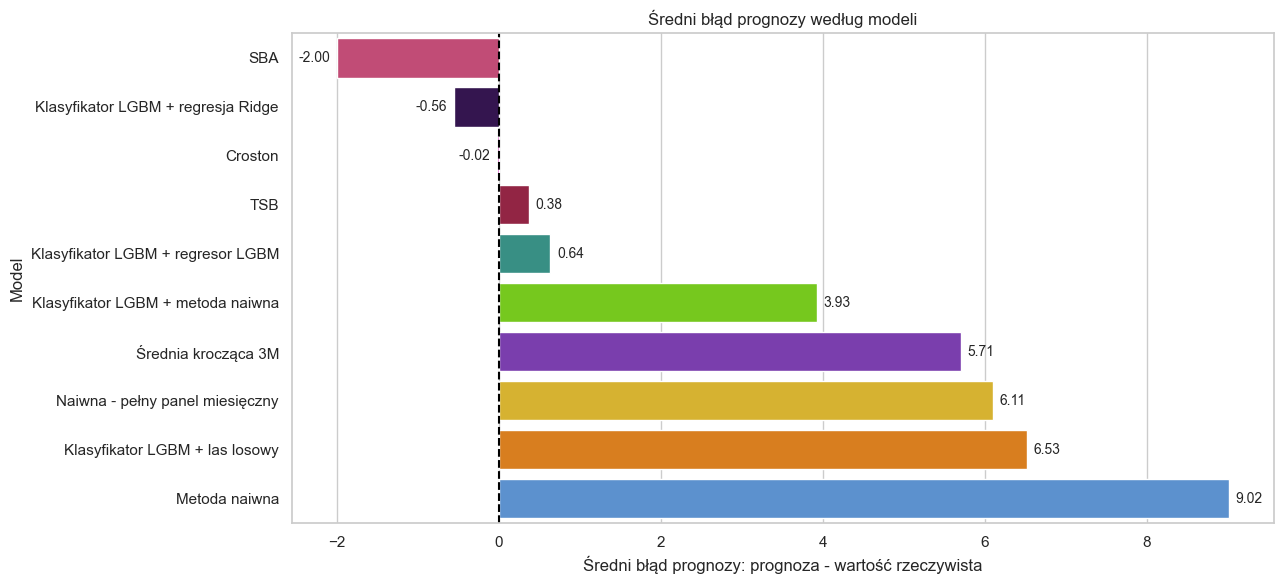

In [717]:
bias_data = all_forecasts_total.copy()

bias_data["model_nazwa"] = bias_data["model"].map(model_labels)
bias_data["blad"] = bias_data["y_pred"] - bias_data["y_true"]

bias_summary = (
    bias_data
    .groupby(["model", "model_nazwa"], observed=True)
    .agg(
        sredni_blad=("blad", "mean"),
        mediana_bledu=("blad", "median")
    )
    .reset_index()
    .sort_values("sredni_blad")
)

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=bias_summary,
    x="sredni_blad",
    y="model_nazwa",
    hue="model_nazwa",
    palette=model_palette,
    legend=False
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

# wartości przy słupkach
for bar in ax.patches:
    width = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2

    if width >= 0:
        ax.text(
            width + 0.08,
            y,
            f"{width:.2f}",
            va="center",
            ha="left",
            fontsize=10
        )
    else:
        ax.text(
            width - 0.08,
            y,
            f"{width:.2f}",
            va="center",
            ha="right",
            fontsize=10
        )

plt.title("Średni błąd prognozy według modeli")
plt.xlabel("Średni błąd prognozy: prognoza - wartość rzeczywista")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

Uzupełnieniem porównania jakości prognoz jest analiza kierunku błędu. Błąd został wyznaczony jako różnica między wartością prognozowaną a rzeczywistą, dlatego jego wartości odpowiadają jednostkom sprzedaży poszczególnych produktów, zgodnie z jednostką, w której rejestrowano ich sprzedaż. Wartości dodatnie oznaczają przeciętne zawyżanie prognoz, wartości ujemne ich zaniżanie, natomiast wartości bliskie zeru wskazują na brak wyraźnej tendencji w jednym kierunku. Najbardziej zrównoważona była metoda Crostona, dla której średni błąd wyniósł -0.02. Niewielkie obciążenie występowało również dla TSB oraz modeli globalnych z regresją Ridge i regresorem LightGBM. SBA wykazywał natomiast tendencję do zaniżania prognoz, ze średnim błędem wynoszącym -2.00.
Znacznie silniejsza tendencja do zawyżania prognoz występowała dla pozostałych metod. Największe obciążenie wykazała zwykła metoda naiwna, dla której średni błąd wyniósł około 9 jednostek sprzedaży. Wyraźne dodatnie błędy występowały również dla modelu z regresorem lasu losowego, benchmarku, średniej kroczącej oraz modelu łączącego klasyfikator LightGBM z metodą naiwną.

,podejscie,liczba_produktow,udzial_proc
0,Modele lokalne,57,54.285714
1,Modele globalne,48,45.714286


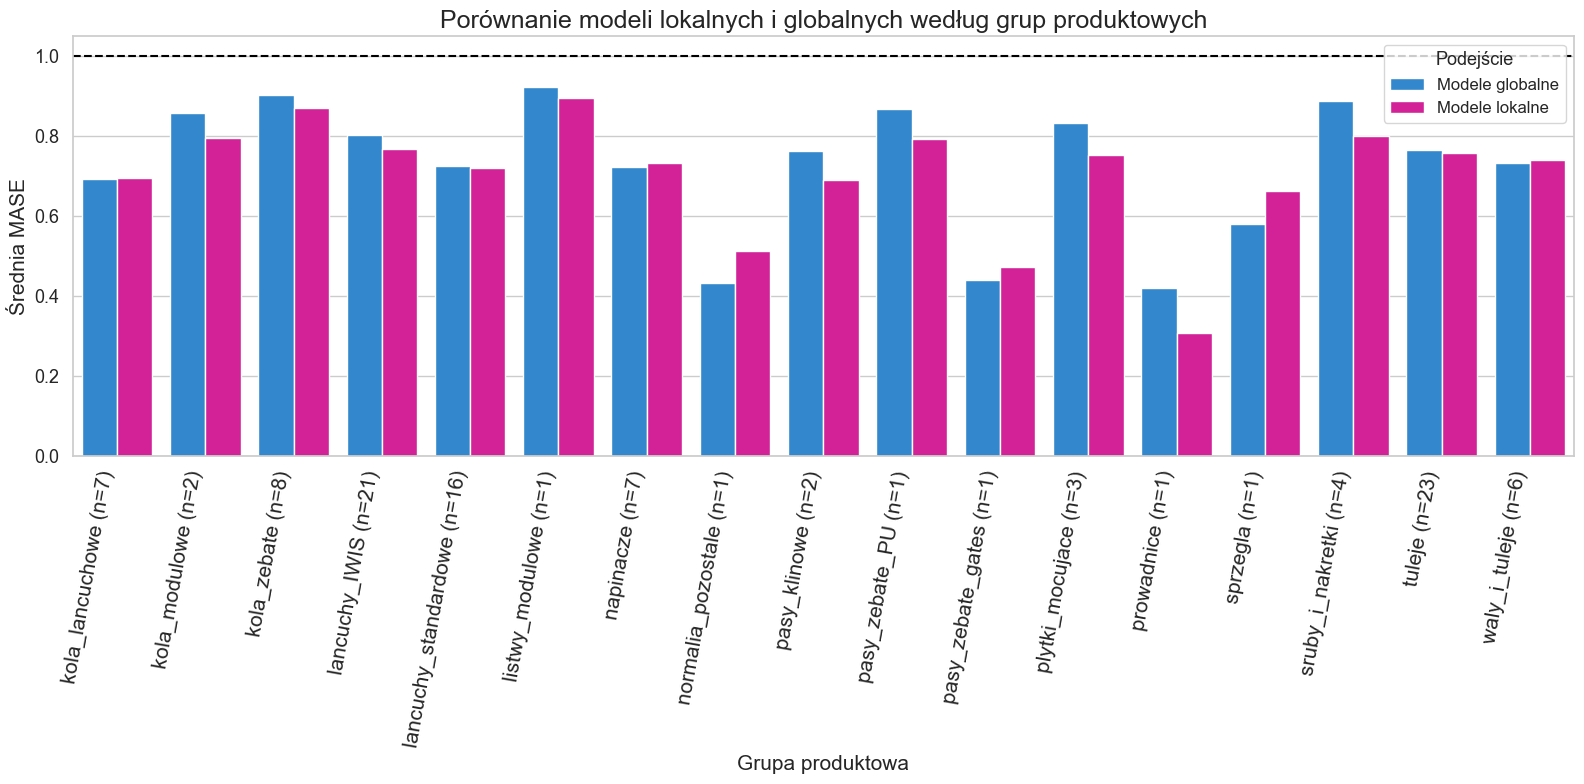

In [718]:
local_models_compare = ["naiwna", "srednia_kroczaca_3", "croston", "sba", "tsb"]

global_models_compare = [
    "lgbm_classifier_ridge",
    "lgbm_classifier_random_forest",
    "lgbm_classifier_lgbm_regressor",
    "lgbm_classifier_naive"
]

def best_model(models, typ):
    return (
        metrics_product_total[metrics_product_total["model"].isin(models)]
        .dropna(subset=["mase"])
        .sort_values(["produkt_id", "mase"])
        .groupby("produkt_id", observed=True)
        .first()
        .reset_index()[["produkt_id", "model", "mase"]]
        .rename(columns={
            "model": f"model_{typ}",
            "mase": f"mase_{typ}"
        })
    )

best_local_product = best_model(local_models_compare, "lokalny")
best_global_product = best_model(global_models_compare, "globalny")

local_global_product = best_local_product.merge(
    best_global_product, on="produkt_id"
)

local_global_product["lepsze_podejscie"] = np.select(
    [
        local_global_product["mase_lokalny"] < local_global_product["mase_globalny"],
        local_global_product["mase_globalny"] < local_global_product["mase_lokalny"]
    ],
    ["Modele lokalne", "Modele globalne"],
    default="Remis"
)

approach_wins = (
    local_global_product["lepsze_podejscie"]
    .value_counts()
    .rename_axis("podejscie")
    .reset_index(name="liczba_produktow")
    .assign(
        udzial_proc=lambda x: x["liczba_produktow"]
        / x["liczba_produktow"].sum() * 100
    )
)

display(approach_wins)

group_comparison = (
    local_global_product
    .merge(
        all_forecasts_total[["produkt_id", "grupa"]].drop_duplicates("produkt_id"),
        on="produkt_id",
        how="left"
    )
    .query("grupa not in ['przeguby', 'kola_klinowe']")
    .copy()
)

if isinstance(group_comparison["grupa"].dtype, pd.CategoricalDtype):
    group_comparison["grupa"] = group_comparison["grupa"].cat.remove_unused_categories()

group_counts = (
    group_comparison.groupby("grupa", observed=True)["produkt_id"]
    .nunique()
)

group_summary = (
    group_comparison
    .melt(
        id_vars=["produkt_id", "grupa"],
        value_vars=["mase_lokalny", "mase_globalny"],
        var_name="podejscie",
        value_name="MASE"
    )
    .assign(
        podejscie=lambda x: x["podejscie"].map({
            "mase_lokalny": "Modele lokalne",
            "mase_globalny": "Modele globalne"
        })
    )
    .groupby(["grupa", "podejscie"], observed=True)["MASE"]
    .mean()
    .reset_index(name="srednia_MASE")
)

group_summary["grupa_n"] = group_summary["grupa"].map(
    lambda x: f"{x} (n={group_counts[x]})"
)

palette = {
    "Modele globalne": "#188AE7",
    "Modele lokalne": "#F104A2"
}

plt.figure(figsize=(16, 8))
sns.barplot(
    data=group_summary,
    x="grupa_n",
    y="srednia_MASE",
    hue="podejscie",
    palette=palette
)

plt.axhline(1, color="black", linestyle="--", linewidth=1.5)
plt.xlabel("Grupa produktowa", fontsize=15)
plt.ylabel("Średnia MASE", fontsize=15)
plt.title("Porównanie modeli lokalnych i globalnych według grup produktowych", fontsize=18)
plt.xticks(rotation=80, ha="right", fontsize=15)
plt.yticks(fontsize=13)
plt.legend(title="Podejście", fontsize=12, title_fontsize=13)
plt.tight_layout()
plt.show()

Jak przedstawiono na powyższym wykresie w 11 z 17 grup niższe wartości MASE uzyskały modele lokalne, jednak skala ich przewagi była zróżnicowana. Wyraźniejsze różnice na korzyść modeli lokalnych wystąpiły m.in. dla pasów klinowych, pasów zębatych PU, płytek mocujących prowadnic oraz śrub i nakrętek. Z kolei modele globalne osiągały niższe średnie MASE m.in. dla normaliów pozostałych, napinaczy oraz sprzęgieł.
Wyniki dla grup obejmujących niewielką liczbę produktów należy interpretować ostrożnie, szczególnie gdy grupa zawiera tylko jeden produkt, ponieważ uzyskany wynik nie jest wówczas reprezentatywny dla szerszej kategorii. W liczniejszych grupach różnice między podejściami były zwykle niewielkie, m.in. dla tulei (n=23), łańcuchów IWIS (n=21) oraz łańcuchów standardowych (n=16). Ogólnie wyniki wskazują, że skuteczność podejścia lokalnego i globalnego była zróżnicowana między grupami produktowymi, choć częściej niższe wartości MASE uzyskiwały modele lokalne.